In [1]:
# Set up the environment and define functions (Python 3.9.12)

# Import packages
import gc
import numpy as np
import matplotlib.pyplot as plt
import os
import os.path as op
import time
import pandas as pd
import glob
import csv
import mne
from mne.preprocessing.nirs import tddr
from nilearn.glm.first_level import make_first_level_design_matrix  
from mne_nirs.channels import get_long_channels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import seaborn as sns
from scipy import signal
from scipy.stats import ttest_rel, zscore
import mne_nirs

mne.viz.set_browser_backend('matplotlib')

######### Set these variables as appropriate:
raw_path = '../../data_DPZ'
proc_path = '../../processed_DPZ'
results_path = '../../results_DPZ'
subjects_dir = '../../subjects_DPZ'
subject_group_mapping = pd.read_csv('../../dpz_blind.csv')
behavior_results_path = '../../fnirs-behavior-results_DPZ'
behavior_file = '../../behavior_diff_data_DPZ.csv'
output_suffix = "DPZ" # used for all file names that are created

# Create the subject to group mapping dictionary
subject_group_mapping = subject_group_mapping.dropna(subset=['Subject'])  
subject_group_mapping['Subject'] = subject_group_mapping['Subject'].astype(int) 
subject_to_group = dict(zip(subject_group_mapping['Subject'], subject_group_mapping['Group']))
subjects = subject_group_mapping['Subject'].astype(str).tolist()

sfreq = 4.807692
conditions = ('A', 'V', 'AV', 'W')
groups = ('DPZ', 'PL')
days = ('1', '3')
runs = (1, 2)

duration = 1.8
design = 'event'
filt_kwargs = dict(
    l_freq=0.01, l_trans_bandwidth=0.01,
    h_freq=0.2, h_trans_bandwidth=0.01)
n_jobs = 4  # for GLM

os.makedirs(proc_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)
os.makedirs(subjects_dir, exist_ok=True)
# mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir, verbose=True)  # Only need to run once

use = None
all_sci = list()
plt.rcParams['axes.titlesize'] = 8
plt.rcParams['axes.labelsize'] = 8
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8

# Prep making bad channels report
bad_channels_filename = op.join(results_path, f'bad_channels_report_{output_suffix}.csv')

with open(bad_channels_filename, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['Subject', 'Day', 'Run', 'Percent Bad'])

def add_bad_channel_entry(subject, day, run, percentage_bad):
    with open(bad_channels_filename, mode='a', newline='') as file:
        writer = csv.writer(file)
        writer.writerow([subject, day, run, f'{percentage_bad:.2f}%'])

def normalize_channel_names(channels_set):
    return {name.split()[0] for name in channels_set}

# Sanity check for subjects
subjects_check = {int(subject) for subject in subjects}
subject_to_group_check = set(subject_to_group.keys())
if subjects_check == subject_to_group_check:
    print("N=" + str(len(subjects)))
    del subjects_check, subject_to_group_check
else:
    print("Error loading subject info") 
    

Using matplotlib as 2D backend.
N=9


In [5]:
# Set parameters for preprocessing

def preprocess_fnirs_data(raw_intensity, proc_path, base):
    # 1. Convert to optical density:
    print(f'    Analyzing {base}')
    raw_od = mne.preprocessing.nirs.optical_density(raw_intensity, verbose='error')

    # 2. Identify bad channels based on flat signal and scalp coupling index:
    peaks = np.ptp(raw_od.get_data('fnirs'), axis=-1)
    flat_names = [raw_od.ch_names[f].split(' ')[0] for f in np.where(peaks < 0.001)[0]]
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od)
    sci_mask = (sci < 0.25)
    got = np.where(sci_mask)[0]
    percentage_bad = (len(got) / len(raw_od.ch_names)) * 100
    assert raw_od.info['bads'] == []
    bads = set(raw_od.ch_names[pick] for pick in got)
    bads = bads | set(ch_name for ch_name in raw_od.ch_names if ch_name.split(' ')[0] in flat_names)
    bads = sorted(bads)

    # 3. Apply temporal derivative distribution repair (TDDR), bandpass filter, apply bad channels:
    raw_tddr = tddr(raw_od)
    raw_tddr_bp = raw_tddr.copy().filter(**filt_kwargs)
    raw_tddr_bp.info['bads'] = bads

    # 5. Short channel regression (if present): 
    try:
        raw_tddr_bp = mne_nirs.signal_enhancement.short_channel_regression(raw_tddr_bp)
        print(f"************** Short channels found for {base}!!")
    except:
        print(f"************** No short channels found for {base}.")

    # 6. Convert to hemoglobin concentration:
    raw_h = mne.preprocessing.nirs.beer_lambert_law(raw_tddr_bp, 6.)

    # 7. Normalize channel names and verify bad channels
    h_bads = [ch_name for ch_name in raw_h.ch_names if ch_name.split(' ')[0] in set(bad.split(' ')[0] for bad in bads)]
    raw_h.info['bads'] = h_bads
    raw_h.info._check_consistency()

    # 8. Select long channels and verify that the signal is not flat:
    raw_h = get_long_channels(raw_h)
    picks = mne.pick_types(raw_h.info, fnirs=True)
    peaks = np.ptp(raw_h.get_data(picks), axis=-1)
    assert (peaks > 1e-9).all()

    # Resample data??
    raw_h = raw_h.resample(sfreq=sfreq)

    # 9. Interpolate bad channels
    if raw_h.info['bads']:
        raw_h_interp = raw_h.copy().interpolate_bads(reset_bads=True, method=dict(fnirs='nearest'))
    else:
        raw_h_interp = raw_h.copy()  # No interpolation needed, just copy
    raw_h_interp.save(op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_{output_suffix}_raw.fif'), overwrite=True)
    assert len(raw_h.ch_names) == len(raw_h_interp.ch_names)

    return raw_h_interp, percentage_bad, bads

In [6]:
# Load participant data

for subject in subjects:
    for day in days:
        for run in runs:
            root1 = f'DPZ_{subject}_Visit{day}'
            root2 = f'*-*-*_{run:03d}'
            fname_base = op.join(raw_path, root1, root2)
            fname = glob.glob(fname_base)
            print(fname)
            base = f'{subject}_{day}_{run:03d}'
            base_pr = base.ljust(20)
            raw_intensity = mne.io.read_raw_nirx(fname[0])
            raw_intensity, percentage_bad_long, bads_long = preprocess_fnirs_data(raw_intensity, proc_path, base + '_long')
            #add_bad_channel_entry(subject, day, run, percentage_bad_long)
            del raw_intensity, percentage_bad_long, bads_long
            gc.collect()  


['../../data_DPZ/DPZ_201_Visit1/2023-06-01_001']
Loading ../../data_DPZ/DPZ_201_Visit1/2023-06-01_001
    Analyzing 201_1_001_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

************** No short channels found for 201_1_001_long.
Sampling frequency of the instance is already 4.807692, returning unmodified.
Overwriting existing file.
Writing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_DPZ/201_1_001_long_hbo_DPZ_raw.fif


[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_DPZ/201_1_001_long_hbo_DPZ_raw.fif
[done]
['../../data_DPZ/DPZ_201_Visit1/2023-06-01_002']
Loading ../../data_DPZ/DPZ_201_Visit1/2023-06-01_002
    Analyzing 201_1_002_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

************** No short channels found for 201_1_002_long.
Sampling frequency of the instance is already 4.807692, returning unmodified.
Overwriting existing file.
Wri

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


['../../data_DPZ/DPZ_201_Visit3/2023-09-10_001']
Loading ../../data_DPZ/DPZ_201_Visit3/2023-09-10_001
    Analyzing 201_3_001_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

************** No short channels found for 201_3_001_long.
Sampling frequency of the instance is already 4.807692, returning unmodified.
Setting channel interpolation method to {'fnirs': 'nearest'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 93.6 mm
Overwriting existing file.
W

...

Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_DPZ/205_1_002_long_hbo_DPZ_raw.fif
[done]
['../../data_DPZ/DPZ_205_Visit3/2023-10-21_001']
Loading ../../data_DPZ/DPZ_205_Visit3/2023-10-21_001
    Analyzing 205_3_001_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

************** No short channels found for 205_3_001_long.
Sampling frequency of the instance is already 4.807692, returning unmodified.
Setting channel interpolation 

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_DPZ/205_3_001_long_hbo_DPZ_raw.fif
[done]
['../../data_DPZ/DPZ_205_Visit3/2023-10-21_002']
Loading ../../data_DPZ/DPZ_205_Visit3/2023-10-21_002
    Analyzing 205_3_002_long
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.01 - 0.2 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.01
- Lower transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.01 Hz)
- Upper passband edge: 0.20 Hz
- Upper transition bandwidth: 0.01 Hz (-6 dB cutoff frequency: 0.21 Hz)
- Filter length: 1587 samples (330.096 s)

************** No short channels found for 205_3_002_long.
Sampling frequency of the instance is already 4.807692, returning unmodified.
Setting channel interpolation 

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done  71 tasks      | elapsed:    0.0s
[Parallel(n_jobs=1)]: Done 161 tasks      | elapsed:    0.0s


Closing /Users/ansle/Documents/GitHub/fnirs-analysis/GithubCode/fnirs-analysis/../../processed_DPZ/205_3_002_long_hbo_DPZ_raw.fif
[done]


In [ ]:
# Remove subjects with >30% bad channels; SKIP

bad_channels_df = pd.read_csv(bad_channels_filename)
bad_channels_df['Percent Bad'] = bad_channels_df['Percent Bad'].str.rstrip('%').astype(float)
average_bad_channels = bad_channels_df.groupby('Subject')['Percent Bad'].mean()

# Find subjects with more than 30% bad channels
bad_subjects = average_bad_channels[average_bad_channels > 30].index.tolist()
print("Subjects with more than 30% bad channels:", bad_subjects)

# Initialize counters for each group
removed_trained = 0
removed_control = 0
remaining_trained = 0
remaining_control = 0

# Count and remove the subjects
for subject in bad_subjects:
    subject_int = int(subject) 
    if subject_int in subject_to_group:
        if subject_to_group[subject_int] == "trained":
            removed_trained += 1
        elif subject_to_group[subject_int] == "control":
            removed_control += 1
        subject_to_group.pop(subject_int, None)

# Update the subjects list after counting the removed subjects
subjects = [subject for subject in subjects if subject not in bad_subjects]        # UNCOMMENT TO REMOVE BAD SUBJECTS
for group in subject_to_group.values():
    if group == "trained":
        remaining_trained += 1
    elif group == "control":
        remaining_control += 1

# Output the results
print(" ")
print(f'Removed {removed_trained} trained subjects.')
print(f'Removed {removed_control} control subjects.')
print(" ")
print(f'Remaining trained subjects: {remaining_trained}')
print(f'Remaining control subjects: {remaining_control}')

# Load the bad channels data
bad_channels_df = pd.read_csv(bad_channels_filename)

# Ensure 'Percent Bad' is treated as a string, strip '%', and convert to float
bad_channels_df['Percent Bad'] = bad_channels_df['Percent Bad'].astype(str).str.rstrip('%').astype(float)

# Sort the DataFrame by 'Percent Bad' in ascending order
bad_channels_df_sorted = bad_channels_df.sort_values(by='Percent Bad')

# Plotting
plt.figure(figsize=(12, 6))
plt.bar(bad_channels_df_sorted['Subject'], bad_channels_df_sorted['Percent Bad'], color='blue', label='Percent Bad Channels')

# Highlight subjects with more than 50% bad channels
plt.bar(bad_channels_df_sorted[bad_channels_df_sorted['Percent Bad'] > 30]['Subject'],
        bad_channels_df_sorted[bad_channels_df_sorted['Percent Bad'] > 30]['Percent Bad'],
        color='red', label='> 30% Bad Channels')

plt.xlabel('Subject')
plt.ylabel('Percent Bad Channels')
plt.title('Percentage of Bad Channels per Subject')
plt.legend()
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability

# Show the plot
plt.tight_layout()
plt.show()

In [ ]:
#subjects.append("209")
#subjects.remove("210")
#print(subjects)


In [ ]:
# Clean events and make design matrix

output_csv = op.join(results_path, f'events_output_{output_suffix}.csv')

def make_design(raw_h_long, design, subject=None, run=None, day=None, group=None):
    annotations_to_remove = raw_h_long.annotations.description == '255.0'
    annotations_to_remove = raw_h_long.annotations.description == '255.0'
    raw_h_long.annotations.delete(annotations_to_remove)
    events, _ = mne.events_from_annotations(raw_h_long)
    
    # Fix mis-codings
    rows_to_remove = events[:, -1] == 1
    events = events[~rows_to_remove]
#    if len(events) == 101:
#        events = events[1:]
    events_df = pd.DataFrame(events, columns=['onset', 'duration', 'trial_type'])
    events_df['subject'] = subject
    events_df['day'] = day
    events_df['run'] = run
    write_header = not os.path.exists(output_csv)  # Write header only if file does not exist
    events_df.to_csv(output_csv, mode='a', index=False, header=write_header)
    n_times = len(raw_h_long.times)
    stim = np.zeros((n_times, 4))
    events[:, 2] -= 1
#    assert len(events) == 100, len(events)
#    want = [0] + [25] * 4
#    count = np.bincount(events[:, 2])
#    assert np.array_equal(count, want), count
#    assert events.shape == (100, 3), events.shape

    if design == 'block':
        events = events[0::5]
        duration = 20.
        assert np.array_equal(np.bincount(events[:, 2]), [0] + [5] * 4)
    else:
#        assert design == 'event'
#        assert len(events) == 100
        duration = 1.8
#        assert events.shape == (100, 3)
#        events_r = events[:, 2].reshape(20, 5)
#        assert (events_r == events_r[:, :1]).all()
#        del events_r
        
    idx = (events[:, [0, 2]] - [0, 1]).T
    assert np.in1d(idx[1], np.arange(len(conditions))).all()
    stim[tuple(idx)] = 1
    
    n_block = int(np.ceil(duration * sfreq))
    stim = signal.fftconvolve(stim, np.ones((n_block, 1)), axes=0)[:n_times]
    dm_events = pd.DataFrame({
        'trial_type': [conditions[ii] for ii in idx[1]],
        'onset': idx[0] / raw_h_long.info['sfreq'],
        'duration': n_block / raw_h_long.info['sfreq']})
    dm = make_first_level_design_matrix(
        raw_h_long.times, dm_events, hrf_model='glover',
        drift_model='polynomial', drift_order=0)
        
    return stim, dm, events

# Run GLM analysis and epoching

subj_cha_list = []
for subject in subjects:
    group = subject_to_group.get(int(subject), "unknown")
    for day in days:
        for run in runs:
            fname_long = op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_{output_suffix}_raw.fif')
            raw_h_long = mne.io.read_raw_fif(fname_long)
            _, dm, _ = make_design(raw_h_long, design, subject, run, day, group)
            glm_est = mne_nirs.statistics.run_glm(
                raw_h_long, dm, noise_model='ols', n_jobs=n_jobs)
            cha = glm_est.to_dataframe()
            cha['subject'] = subject
            cha['run'] = run
            cha['day'] = day
            cha['group'] = group
            subj_cha_list.append(cha)
            del raw_h_long, dm, glm_est, cha
            gc.collect()  #
        print(f'***Finished processing subject {subject} day {day}.')

df_cha = pd.concat(subj_cha_list, ignore_index=True)
df_cha.reset_index(drop=True, inplace=True)


In [ ]:
# Change the subject, day, and run to plot different waveforms; SKIP

plot_subject = '210'
plot_day = 1
plot_run = 1

fname2 = op.join(proc_path, f'{plot_subject}_{plot_day}_{plot_run:03d}_long_hbo_{output_suffix}_raw.fif')
use = mne.io.read_raw_fif(fname2, preload=True)
events, _ = mne.events_from_annotations(use)
ch_names = [ch_name.rstrip(' hbo') for ch_name in use.ch_names]
info = use.info

fig, axes = plt.subplots(2, 1, figsize=(6., 3), constrained_layout=True)
ax = axes[0]
raw_h = use
stim, dm, _ = make_design(raw_h, design)

colors = dict(
    A='#4477AA',  # blue
    AV='#CCBB44',  # yellow
    V='#EE7733',  # orange
    W='#AA3377',  # purple
)

for ci, condition in enumerate(conditions):
    color = colors[condition]
    ax.fill_between(
        raw_h.times, stim[:, ci], 0, edgecolor='none', facecolor='k',
        alpha=0.5)
    model = dm[conditions[ci]].to_numpy()
    ax.plot(raw_h.times, model, ls='-', lw=1, color=color)
    x = raw_h.times[np.where(model > 0)[0][0]]
    ax.text(
        x + 10, 1.1, condition, color=color, fontweight='bold', ha='center')
ax.set(ylabel='Modeled\noxyHb', xlabel='', xlim=raw_h.times[[0, -1]])

# HbO/HbR
ax = axes[1]
picks = [pi for pi, ch_name in enumerate(raw_h.ch_names)
         if 'S7_D19' in ch_name]
colors = dict(hbo='r', hbr='b')
ylim = np.array([-1, 1])
for pi, pick in enumerate(picks):
    color = colors[raw_h.ch_names[pick][-3:]]
    data = raw_h.get_data(pick)[0] * 1e6
    val = np.ptp(data)
    assert val > 0.01
    ax.plot(raw_h.times, data, color=color, lw=1.)
ax.set(ylim=ylim, xlabel='Time (s)', ylabel='μM',
       xlim=raw_h.times[[0, -1]])
for ax in axes:
    for key in ('top', 'right'):
        ax.spines[key].set_visible(False)
plt.savefig(op.join(results_path, f'figure_1_{output_suffix}.png'))


In [ ]:
# Block averages

event_id = {condition: ci for ci, condition in enumerate(conditions, 1)}
evokeds = {condition: dict() for condition in conditions}
for day in days:
    for subject in subjects:
        fname = op.join(proc_path, f'{subject}_{day}_{output_suffix}-ave.fif')
        tmin, tmax = -2, 38
        baseline = (None, 0)
        t0 = time.time()
        print(f'Creating block average for {subject} day {day}... ', end='')
        raws = list()
        events = list()
        for run in runs:
            fname2 = op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_{output_suffix}_raw.fif')
            raw_h = mne.io.read_raw_fif(fname2)
            events.append(make_design(raw_h, None, 'block', subject, run)[2])
            raws.append(raw_h)
        bads = sorted(set(sum((r.info['bads'] for r in raws), [])))
        for r in raws:
            r.info['bads'] = bads
        raw_h, events = mne.concatenate_raws(raws, events_list=events)
        epochs = mne.Epochs(raw_h, events, event_id, tmin=tmin, tmax=tmax,
                            baseline=baseline)
        this_ev = [epochs[condition].average() for condition in conditions]
        assert all(ev.nave > 0 for ev in this_ev)
        mne.write_evokeds(fname, this_ev, overwrite=True)
        print(f'{time.time() - t0:0.1f} sec')
        for condition in conditions:
            evokeds[condition][subject] = mne.read_evokeds(fname, condition)
        print(f'Done for {group} {subject} day {day} run {run:03d}... ', end='')
        del raws, events, raw_h, epochs, this_ev
        gc.collect()  #

# Mark bad channels
bad = dict()
bb = dict()

for day in days:
    for subject in subjects:
        for run in runs:
            fname2 = op.join(proc_path, f'{subject}_{day}_{run:03d}_long_hbo_{output_suffix}_raw.fif')
            this_info = mne.io.read_info(fname2)
            bad_channels = [idx - 1 for idx in sorted(
                this_info['ch_names'].index(bad) + 1 for bad in this_info['bads'])]
            valid_indices = np.arange(len(use.ch_names))
            bb = [b for b in bad_channels if b in valid_indices]
            bad[(subject, run, day)] = bb
        assert np.in1d(bad[(subject, run, day)], np.arange(len(use.ch_names))).all()

bad_combo = dict()
for day in days:
    for (subject, run, day), bb in bad.items():
        bad_combo[subject] = sorted(set(bad_combo.get(subject, [])) | set(bb))
bad = bad_combo

start = len(df_cha)
n_drop = 0
for day in days:
    for (subject, run, day), bb in bad.items():
        if not len(bb):
            continue
        drop_names = [use.ch_names[b] for b in bb]
        is_subject = (df_cha['subject'] == subject)
        is_day = (df_cha['day'] == day)
        drop = df_cha.index[
            is_subject &
            is_day &
            np.in1d(df_cha['ch_name'], drop_names)]
        n_drop += len(drop)
        if len(drop):
            print(f'Dropping {len(drop)} for {subject} day {day}')
            df_cha.drop(drop, inplace=True)
end = len(df_cha)
assert n_drop == start - end, (n_drop, start - end)

# Combine runs by averaging
sorts = ['subject', 'ch_name', 'Chroma', 'Condition', 'group', 'day', 'run']
df_cha.sort_values(sorts, inplace=True)
theta = np.array(df_cha['theta']).reshape(-1, len(runs)).mean(-1)
df_cha.drop(
    [col for col in df_cha.columns if col not in sorts[:-1]], axis='columns',
    inplace=True)
df_cha.reset_index(drop=True, inplace=True)
df_cha = df_cha[::len(runs)]
df_cha.reset_index(drop=True, inplace=True)
df_cha['theta'] = theta

In [ ]:
# Calculate HbDiff

# Load the data
df_cha_nolabels = df_cha.copy()
df_cha_nolabels['ch_name'] = df_cha_nolabels['ch_name'].str[:-4]  # Remove HbO/HbR suffix

# Separate HbO and HbR
df_hbo = df_cha_nolabels[df_cha_nolabels['Chroma'].str.endswith('hbo')].set_index(
    ['subject', 'Condition', 'group', 'day', 'ch_name']
).sort_index()
df_hbr = df_cha_nolabels[df_cha_nolabels['Chroma'].str.endswith('hbr')].set_index(
    ['subject', 'Condition', 'group', 'day', 'ch_name']
).sort_index()

# Compute HbDiff (HbO - HbR)
df_hbdiff_list = []
for ch_name in df_hbo.index.get_level_values('ch_name').unique():
    # Get aligned indices
    df_hbo_ch = df_hbo.loc[(slice(None), slice(None), slice(None), slice(None), ch_name), :].sort_index()
    df_hbr_ch = df_hbr.loc[(slice(None), slice(None), slice(None), slice(None), ch_name), :].sort_index()
    
    # Ensure df_hbo_ch and df_hbr_ch have the same length
    common_index = df_hbo_ch.index.intersection(df_hbr_ch.index)
    df_hbo_ch = df_hbo_ch.loc[common_index]
    df_hbr_ch = df_hbr_ch.loc[common_index]
    
    # Calculate the difference
    df_diff = df_hbo_ch[['theta']].sub(df_hbr_ch[['theta']])
    
    # Create a DataFrame for HbDiff
    df_hbdiff_ch = df_hbo_ch.reset_index()
    df_hbdiff_ch['theta'] = df_diff.values
    df_hbdiff_ch['Chroma'] = 'hbdiff'  # Change Chroma label to 'hbdiff'
    
    if not df_hbdiff_ch.empty:
        df_hbdiff_list.append(df_hbdiff_ch)

# Combine HbDiff results into a single DataFrame
df_hbdiff_final = pd.concat(df_hbdiff_list, ignore_index=True)

# Save only the HbDiff results to CSV
output_file = op.join(results_path, f'df_hbdiff_{output_suffix}_n9.csv')
df_hbdiff_final.to_csv(output_file, index=False)

print(f'Saved HbDiff results to {output_file}')


####################################

<h1>Correlational Analyses</h1>

####################################


In [2]:
import os.path as op
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ValueWarning
import warnings
warnings.filterwarnings("ignore", category=ValueWarning) 
warnings.filterwarnings("ignore", category=UserWarning) 
from scipy.stats import ttest_rel, zscore

import mne 
import numpy as np
import gc
import re

raw_path = '../../data_DPZ'
proc_path = '../../processed_DPZ'
results_path = '../../results_DPZ'
subjects_dir = '../../subjects_DPZ'
subject_group_mapping = pd.read_csv('../../dpz_blind.csv')
behavior_results_path = '../../fnirs-behavior-results_DPZ'
output_suffix = 'DPZ'
df_final = pd.read_csv(op.join(results_path, f'df_combined_final_cha_{output_suffix}_nodiff.csv'))

mne.viz.set_3d_backend('pyvistaqt')  # or 'notebook' if you're in Jupyter

plot_subject = '207'
plot_day = 1
plot_run = 1
fname2 = op.join(proc_path, f'{plot_subject}_{plot_day}_{plot_run:03d}_long_hbo_{output_suffix}_raw.fif')
use = mne.io.read_raw_fif(fname2, preload=True)
events, _ = mne.events_from_annotations(use)
info = use.info

groups = ['DPZ', 'PL']
conditions = ['A']
chromas = ['hbo']
#chromas = ['hbo', 'hbr', 'hbdiff']
#response_vars = ['AO_WR', 'AV_WR', 'TBW']
#days = [1, 3]


Using pyvistaqt 3d backend.
Opening raw data file ../../processed_DPZ/207_1_001_long_hbo_DPZ_raw.fif...
    Range : 0 ... 3528 =      0.000 ...   733.824 secs
Ready.
Reading 0 ... 3528  =      0.000 ...   733.824 secs...
Used Annotations descriptions: ['1.0', '2.0', '3.0', '4.0', '5.0']


In [4]:
# Plot significant Channel : Condition interactions!!! This works!
import numpy as np
print(np.__version__)

# Perform analysis for each group and Chroma
for group in groups:
    for chroma in chromas:
        for condition in conditions:
            # Filter data for day 1 and day 3 for the specific group and Chroma
            df_day1 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 1 and Condition == '{condition}'").copy()
            df_day3 = df_final.query(f"group == '{group}' and Chroma == '{chroma}' and day == 3 and Condition == '{condition}'").copy()

            # Check if there is data for day 1 and day 3
            if df_day1.empty or df_day3.empty:
                print(f"No data found for Group: {group}, Condition: {condition}, Chroma: {chroma}. Skipping...")
                continue

            # Ensure ch_name is of the same data type
            df_day1['ch_name'] = df_day1['ch_name'].astype(str)
            df_day3['ch_name'] = df_day3['ch_name'].astype(str)

            # Set index and sort
            df_day1 = df_day1.set_index(['subject', 'group', 'ch_name', 'Condition', 'Chroma']).sort_index()
            df_day3 = df_day3.set_index(['subject', 'group', 'ch_name', 'Condition', 'Chroma']).sort_index()

            # Check if there are subjects in common between Day 1 and Day 3
            merged_subjects = df_day1.index.get_level_values('subject').intersection(df_day3.index.get_level_values('subject')).unique()
            if merged_subjects.empty:
                print(f"No matching subjects for Group: {group}, Condition: {condition}, Chroma: {chroma}. Skipping...")
                continue

            for subject in merged_subjects:
                subject_day1 = df_day1.loc[df_day1.index.get_level_values('subject') == subject]
                subject_day3 = df_day3.loc[df_day3.index.get_level_values('subject') == subject]

                # Check if data is available for the subject on both days
                if subject_day1.empty or subject_day3.empty:
                    print(f"No data for Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}. Skipping...")
                    continue

                info = use.info
                hbo_indices = [idx for idx, ch in enumerate(info['ch_names']) if ch.endswith(chroma)]
                info_chroma = mne.pick_info(info, sel=hbo_indices)

                # Prepare data for Day 1
                z_day1 = zscore(subject_day1['theta'].values)
                evoked_day1 = mne.EvokedArray(data=np.expand_dims(z_day1, axis=1), info=info_chroma)

                # Prepare data for Day 3
                z_day3 = zscore(subject_day3['theta'].values)
                evoked_day3 = mne.EvokedArray(data=np.expand_dims(z_day3, axis=1), info=info_chroma)

                # Visualize Day 1 on the brain
                stc_day1 = mne.stc_near_sensors(
                    evoked_day1, trans='fsaverage', subject='fsaverage', mode='weighted',
                    distance=0.03, project=True, picks=np.arange(len(info_chroma['ch_names'])),
                    subjects_dir=subjects_dir)

                brain_day1 = stc_day1.plot(
                    hemi='both', views=['lat', 'frontal', 'lat'], view_layout='horizontal',
                    time_viewer=False, show_traces=False, surface='pial', smoothing_steps=0,
                    size=(1200, 400), clim=dict(kind='value', lims=[-3.0, 0, 3.0]), colormap='RdBu',
                    colorbar=(0, 1), time_label='', background='w',
                    brain_kwargs=dict(units='m'),
                    add_data_kwargs=dict(colorbar_kwargs=dict(
                        title_font_size=12, label_font_size=8, n_labels=3, title='   ')),
                    subjects_dir=subjects_dir)
                brain_day1.screenshot(time_viewer=False)
                brain_day1.save_image(op.join(results_path, f'{subject}_Day1_{group}_{condition}_{chroma}_brain_plot.png'))
                brain_day1.close()

                # Visualize Day 3 on the brain
                stc_day3 = mne.stc_near_sensors(
                    evoked_day3, trans='fsaverage', subject='fsaverage', mode='weighted',
                    distance=0.03, project=True, picks=np.arange(len(info_chroma['ch_names'])),
                    subjects_dir=subjects_dir)

                brain_day3 = stc_day3.plot(
                    hemi='both', views=['lat', 'frontal', 'lat'], view_layout='horizontal',
                    time_viewer=False, show_traces=False, surface='pial', smoothing_steps=0,
                    size=(1200, 400), clim=dict(kind='value', lims=[-3.0, 0, 3.0]), colormap='RdBu',
                    colorbar=(0, 1), time_label='', background='w',
                    brain_kwargs=dict(units='m'),
                    add_data_kwargs=dict(colorbar_kwargs=dict(
                        title_font_size=12, label_font_size=8, n_labels=3, title='   ')),
                    subjects_dir=subjects_dir)
                brain_day3.screenshot(time_viewer=False)
                brain_day3.save_image(op.join(results_path, f'{subject}_Day3_{group}_{condition}_{chroma}_brain_plot.png'))
                brain_day3.close()

                print(f"Saved brain plots for Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}.")


1.23.5
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    236899 / 327684 non-zero vertices
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    236899 / 327684 non-zero vertices
Saved brain plots for Subject: 201.0, Group: DPZ, Condition: A, Chroma: hbo.
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    236899 / 327684 non-zero vertices
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    236899 / 327684 non-zero vertices
Saved brain plots for Subject: 204.0, Group: DPZ, Condition: A, Chroma: hbo.
Projecting data from 84 sensors

KeyboardInterrupt: 

In [ ]:
#pip install numpy==1.23.5 # downgraded from numpy 1.26.4


In [3]:
# Plot significant changes day 3 vs day 1 t-test!!!

from scipy.stats import ttest_rel
import mne
import numpy as np

conditions = ['A']
groups = ['DPZ', 'PL']
chromas = ['hbo']
results = []

# Perform paired t-tests for significant changes
for chroma in chromas:
    for condition in conditions:
        for group in groups:
            df_filtered = df_final.query(
                f"group == '{group}' and Chroma == '{chroma}' and Condition == '{condition}'"
            ).copy()            
            subjects = df_filtered['subject'].unique()
            df_filtered['day'] = df_filtered['day'].astype(float)
            df_filtered['subject'] = df_filtered['subject'].astype(float)
            
            for subject in subjects:
                print(f"Processing Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}")
                
                # Filter data for Day 1 and Day 3
                df_day1 = df_filtered[(df_filtered['day'] == 1.0) & (df_filtered['subject'] == subject)]
                df_day3 = df_filtered[(df_filtered['day'] == 3.0) & (df_filtered['subject'] == subject)]
                
                # Ensure data is matched by channel
                channels_day1 = np.sort(df_day1['ch_name'].values)
                channels_day3 = np.sort(df_day3['ch_name'].values)
                
                # Find common channels between Day 1 and Day 3
                common_channels = np.intersect1d(channels_day1, channels_day3)
                if len(common_channels) == 0:
                    print(f"No common channels for Subject: {subject}, Skipping...")
                    continue
                
                # Pair Day 1 and Day 3 data
                day1_values = df_day1.set_index('ch_name').loc[common_channels, 'theta'].values
                day3_values = df_day3.set_index('ch_name').loc[common_channels, 'theta'].values
                
                # Run paired t-test
                t_stat, p_values = ttest_rel(day1_values, day3_values)
                
                # Adjust p-values using FDR correction
                _, p_values_fdr = mne.stats.fdr_correction(p_values, alpha=0.05, method='indep')
                
                # Identify significant channels
                significant_channels = common_channels[p_values_fdr < 0.05]
                significant_channels = np.array(significant_channels).flatten().tolist()
                if len(significant_channels) == 0:
                    print(f"No significant changes for Subject: {subject}. Skipping plot...")
                    continue
                
                print(f"Significant channels: {significant_channels}")
                
                # Prepare data for plotting
                z_day1 = zscore(df_day1.set_index('ch_name').loc[significant_channels, 'theta'].values)
                z_day3 = zscore(df_day3.set_index('ch_name').loc[significant_channels, 'theta'].values)
                
                info = use.info
                sig_indices = [idx for idx, ch in enumerate(info['ch_names']) if ch in significant_channels]
                info_sig = mne.pick_info(info, sel=sig_indices)
                
                evoked_day1 = mne.EvokedArray(data=np.expand_dims(z_day1, axis=1), info=info_sig)
                evoked_day3 = mne.EvokedArray(data=np.expand_dims(z_day3, axis=1), info=info_sig)
                
                # Plot significant channels
                stc_day1 = mne.stc_near_sensors(
                    evoked_day1, trans='fsaverage', subject='fsaverage', mode='weighted',
                    distance=0.03, project=True, picks=np.arange(len(info_sig['ch_names'])),
                    subjects_dir=subjects_dir)
                
                brain_day1 = stc_day1.plot(
                    hemi='both', views=['lat', 'frontal', 'lat'], view_layout='horizontal',
                    time_viewer=False, show_traces=False, surface='pial', smoothing_steps=0,
                    size=(1200, 400), clim=dict(kind='value', lims=[-3.0, 0, 3.0]), colormap='RdBu',
                    colorbar=(0, 1), time_label='', background='w',
                    brain_kwargs=dict(units='m'),
                    add_data_kwargs=dict(colorbar_kwargs=dict(
                        title_font_size=12, label_font_size=8, n_labels=3, title='   ')),
                    subjects_dir=subjects_dir)
                
                brain_day1.screenshot(time_viewer=False)
                brain_day1.save_image(op.join(results_path, f'{subject}_Day1_{group}_{condition}_{chroma}_sig_brain_plot.png'))
                brain_day1.close()

                # Plot significant channels
                stc_day3 = mne.stc_near_sensors(
                    evoked_day3, trans='fsaverage', subject='fsaverage', mode='weighted',
                    distance=0.03, project=True, picks=np.arange(len(info_sig['ch_names'])),
                    subjects_dir=subjects_dir)
                
                brain_day3 = stc_day3.plot(
                    hemi='both', views=['lat', 'frontal', 'lat'], view_layout='horizontal',
                    time_viewer=False, show_traces=False, surface='pial', smoothing_steps=0,
                    size=(1200, 400), clim=dict(kind='value', lims=[-3.0, 0, 3.0]), colormap='RdBu',
                    colorbar=(0, 1), time_label='', background='w',
                    brain_kwargs=dict(units='m'),
                    add_data_kwargs=dict(colorbar_kwargs=dict(
                        title_font_size=12, label_font_size=8, n_labels=3, title='   ')),
                    subjects_dir=subjects_dir)
                
                brain_day3.screenshot(time_viewer=False)
                brain_day3.save_image(op.join(results_path, f'{subject}_Day3_{group}_{condition}_{chroma}_sig_brain_plot.png'))
                brain_day3.close()

                print(f"Saved significant brain plot for Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}.")


Processing Subject: 201.0, Group: DPZ, Condition: A, Chroma: hbo
No significant changes for Subject: 201.0. Skipping plot...
Processing Subject: 204.0, Group: DPZ, Condition: A, Chroma: hbo
No significant changes for Subject: 204.0. Skipping plot...
Processing Subject: 209.0, Group: DPZ, Condition: A, Chroma: hbo
No significant changes for Subject: 209.0. Skipping plot...
Processing Subject: 212.0, Group: DPZ, Condition: A, Chroma: hbo
Significant channels: ['S10_D18 hbo', 'S10_D20 hbo', 'S10_D22 hbo', 'S11_D19 hbo', 'S11_D21 hbo', 'S11_D23 hbo', 'S12_D20 hbo', 'S12_D21 hbo', 'S12_D22 hbo', 'S12_D24 hbo', 'S13_D21 hbo', 'S13_D23 hbo', 'S13_D24 hbo', 'S13_D25 hbo', 'S14_D22 hbo', 'S14_D24 hbo', 'S14_D26 hbo', 'S15_D11 hbo', 'S15_D14 hbo', 'S15_D25 hbo', 'S16_D14 hbo', 'S16_D25 hbo', 'S16_D26 hbo', 'S16_D27 hbo', 'S17_D13 hbo', 'S17_D14 hbo', 'S17_D27 hbo', 'S18_D26 hbo', 'S18_D27 hbo', 'S19_D4 hbo', 'S19_D6 hbo', 'S19_D8 hbo', 'S1_D2 hbo', 'S1_D4 hbo', 'S20_D3 hbo', 'S20_D5 hbo', 'S20_D

2025-09-07 21:30:26.865 python[55725:1521870] +[IMKClient subclass]: chose IMKClient_Modern
2025-09-07 21:30:26.865 python[55725:1521870] +[IMKInputSession subclass]: chose IMKInputSession_Modern
2025-09-07 21:30:26.906 python[55725:1521870] NSKeyBindingManager: Bad key binding selector for '^z' = 'undo:'


    Minimum projected intra-sensor distance: 6.1 mm
    236899 / 327684 non-zero vertices
Saved significant brain plot for Subject: 212.0, Group: DPZ, Condition: A, Chroma: hbo.
Processing Subject: 203.0, Group: PL, Condition: A, Chroma: hbo
No significant changes for Subject: 203.0. Skipping plot...
Processing Subject: 205.0, Group: PL, Condition: A, Chroma: hbo
Significant channels: ['S10_D18 hbo', 'S10_D20 hbo', 'S10_D22 hbo', 'S11_D19 hbo', 'S11_D21 hbo', 'S11_D23 hbo', 'S12_D20 hbo', 'S12_D21 hbo', 'S12_D22 hbo', 'S12_D24 hbo', 'S13_D21 hbo', 'S13_D23 hbo', 'S13_D24 hbo', 'S13_D25 hbo', 'S14_D22 hbo', 'S14_D24 hbo', 'S14_D26 hbo', 'S15_D11 hbo', 'S15_D14 hbo', 'S15_D25 hbo', 'S16_D14 hbo', 'S16_D25 hbo', 'S16_D26 hbo', 'S16_D27 hbo', 'S17_D13 hbo', 'S17_D14 hbo', 'S17_D27 hbo', 'S18_D26 hbo', 'S18_D27 hbo', 'S19_D4 hbo', 'S19_D6 hbo', 'S19_D8 hbo', 'S1_D2 hbo', 'S1_D4 hbo', 'S20_D3 hbo', 'S20_D5 hbo', 'S20_D6 hbo', 'S20_D7 hbo', 'S21_D10 hbo', 'S21_D6 hbo', 'S21_D7 hbo', 'S21_D8 h

In [ ]:
# Plot individual hbdiff z-scores for all channels
 
conditions = ['A']
groups = ['DPZ', 'PL']
chromas = ['hbo']

df_final = pd.read_csv(op.join(results_path, f'df_combined_final_cha_final.csv'))

from matplotlib import cm
from matplotlib.colors import ListedColormap

# Customize the RdBu colormap to ensure a deep red at the lower end
original_cmap = cm.get_cmap('RdBu_r', 256)
custom_cmap = ListedColormap(original_cmap(np.linspace(0, 1, 256)))

for chroma in chromas:
    for condition in conditions:
        for group in groups:
            df_filtered = df_final.query(
                f"group == '{group}' and Chroma == '{chroma}' and Condition == '{condition}'"
            ).copy()
            subjects = df_filtered['subject'].unique()
            df_filtered['day'] = df_filtered['day'].astype(float)
            df_filtered['subject'] = df_filtered['subject'].astype(float)

            for subject in subjects:
                print(f"Processing Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}")

                # Filter data for Day 1 and Day 3
                df_day1 = df_filtered[(df_filtered['day'] == 1.0) & (df_filtered['subject'] == subject)]
                df_day3 = df_filtered[(df_filtered['day'] == 3.0) & (df_filtered['subject'] == subject)]

                # Clean channel names
                channels_day1 = df_day1['ch_name'].values
                channels_day3 = df_day3['ch_name'].values
                cleaned_channels_day1 = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in channels_day1]
                cleaned_channels_day3 = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in channels_day3]
                cleaned_info_ch_names = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in info['ch_names']]

                # Find common channels
                common_channels = np.intersect1d(cleaned_channels_day1, cleaned_channels_day3)
                channel_mapping = {ch: idx for idx, ch in enumerate(cleaned_info_ch_names)}
                all_indices = [channel_mapping[ch] for ch in common_channels if ch in channel_mapping]

                if len(all_indices) == 0:
                    print(f"No matching channels for Subject: {subject}. Skipping...")
                    continue

                # Prepare info
                info_all = mne.pick_info(info, sel=all_indices)

                # Map cleaned channel names back to original names
                original_channel_mapping_day1 = {re.sub(r" (hbo|hbr|hbdiff)$", "", ch): ch for ch in channels_day1}
                original_channel_mapping_day3 = {re.sub(r" (hbo|hbr|hbdiff)$", "", ch): ch for ch in channels_day3}
                mapped_channels_day1 = [original_channel_mapping_day1[ch] for ch in common_channels if ch in original_channel_mapping_day1]
                mapped_channels_day3 = [original_channel_mapping_day3[ch] for ch in common_channels if ch in original_channel_mapping_day3]

                # Get theta values and compute z-scores
                z_day1 = zscore(df_day1.set_index('ch_name').loc[mapped_channels_day1, 'theta'].values)
                z_day3 = zscore(df_day3.set_index('ch_name').loc[mapped_channels_day3, 'theta'].values)

                # Compute Day 3 - Day 1 z-scores
                z_diff = z_day3 - z_day1

                # Ensure data matches the number of channels in info_all
                if z_diff.shape[0] != len(info_all['ch_names']):
                    print(f"Mismatch between z-scores and info channels for Subject: {subject}. Skipping...")
                    continue

                # Create the EvokedArray
                evoked_diff = mne.EvokedArray(data=np.expand_dims(z_diff, axis=1), info=info_all)

                # Plot the difference brain
                stc_diff = mne.stc_near_sensors(
                    evoked_diff, trans='fsaverage', subject='fsaverage', mode='weighted',
                    distance=0.03, project=True, picks=np.arange(len(info_all['ch_names'])),
                    subjects_dir=subjects_dir)

                brain_diff = stc_diff.plot(
                    hemi='both', views=['lateral', 'coronal', 'sagittal'], view_layout='horizontal',
                    time_viewer=False, show_traces=False, surface='pial', smoothing_steps=0,
                    size=(1200, 400), 
                    clim=dict(kind='value', lims=[-3.0, 0.0, 3.0]), 
                    colormap=custom_cmap,  # Use the custom colormap
                    time_label='', background='w',
                    brain_kwargs=dict(units='m'),
                    add_data_kwargs=dict(colorbar_kwargs=dict(
                        title_font_size=12, label_font_size=8, n_labels=3, title='   ')),
                    subjects_dir=subjects_dir)

                # Save the plot
                brain_diff.screenshot(time_viewer=False)
                brain_diff.save_image(os.path.join(results_path, f'{subject}_Change_{group}_{condition}_{chroma}_brain_plot.png'))
                brain_diff.close()

                print(f"Saved Day 3 - Day 1 brain plot for Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}.")


In [ ]:
# Calculate z scores values and merge landmarks

df_final = pd.read_csv(op.join(results_path, f'df_combined_final_cha_DPZ.csv'))
z_diff_output_file = f"{results_path}/zscores_final_n9.csv"
specificity_df = pd.read_csv(op.join(results_path, 'hemi_specificity.csv'))
chromas = ['hbdiff', 'hbo', 'hbr']
conditions = ['A', 'AV', 'V']

z_diff_records = []  # To store all records

for chroma in chromas:
    for condition in conditions:
        # Filter data for the current chroma and condition
        df_condition = df_final.query(f"Chroma == '{chroma}' and Condition == '{condition}'").copy()
        df_condition['day'] = df_condition['day'].astype(float)
        df_condition['subject'] = df_condition['subject'].astype(float)

        for group in groups:
            print(f"Processing Group: {group}, Condition: {condition}, Chroma: {chroma}")

            # Filter data for the current group
            df_group = df_condition[df_condition['group'] == group]

            # Calculate per-participant z-scores for Day 1 and Day 3
            per_subject_z_scores = []
            subjects = df_group['subject'].unique()

            for subject in subjects:
                df_subject = df_group[df_group['subject'] == subject]
                df_day1 = df_subject[df_subject['day'] == 1.0].set_index('ch_name')['theta']
                df_day3 = df_subject[df_subject['day'] == 3.0].set_index('ch_name')['theta']

                if not df_day1.empty and not df_day3.empty:
                    # Compute z-scores for this participant
                    common_channels = df_day1.index.intersection(df_day3.index)
                    z_day1 = zscore(df_day1.loc[common_channels])
                    z_day3 = zscore(df_day3.loc[common_channels])
                    z_diff = z_day3 - z_day1

                    # Store z_day1, z_day3, and z_diff for this participant
                    for idx, channel in enumerate(common_channels):
                        z_diff_records.append({
                            'group': group,
                            'subject': subject,  # Add this line
                            'condition': condition,
                            'chroma': chroma,
                            'channel': channel,
                            'z_day1': z_day1[idx],
                            'z_day3': z_day3[idx],
                            'z_diff': z_diff[idx]
                        })

# Normalize and clean channel names in the specificity dataset
specificity_df['ch_name'] = (
    specificity_df['ch_name']
    .str.replace(r" hbo$", "", regex=True)  # Remove suffixes like " hbo"
    .str.strip()
    .str.lower()
)

# Normalize and clean channel names in the z_diff_records
for record in z_diff_records:
    record['channel'] = (
        record['channel']
        .replace(" hbdiff", "")  # Remove suffixes like " hbo" to match specificity_df
        .strip()
        .lower()
    )

# Create a DataFrame for z_diff records
df_zdiff = pd.DataFrame(z_diff_records)

# Merge with specificity data
merged_df = df_zdiff.merge(
    specificity_df[['ch_name', 'Landmark', 'Specificity', 'Hemisphere']],
    left_on='channel',
    right_on='ch_name',
    how='left'
)

# Debugging: Check for missing landmarks or specificity
missing_data = merged_df[merged_df['Landmark'].isna()]
if not missing_data.empty:
    print("Missing landmark and specificity for the following channels:")
    print(missing_data['channel'].unique())

# Drop redundant column
merged_df = merged_df.drop(columns=['ch_name'])

# Save the resulting DataFrame to a CSV file
merged_df.to_csv(z_diff_output_file, index=False)

print(f"z_day1, z_day3, and z_diff values with landmarks and specificity saved to {z_diff_output_file}")


In [ ]:
# Plot group average z_diff for hbdiff z-scores - SKIP
import pandas as pd
import numpy as np
from scipy.stats import zscore
from matplotlib import cm
from matplotlib.colors import ListedColormap
import mne
import os
import re

# Define conditions, groups, and chromas
conditions = ['A']
groups = ['DPZ', 'PL']
chromas = ['hbdiff']

# Load the combined data
df_final = pd.read_csv(op.join(results_path, f'df_combined_final_cha_{output_suffix}.csv'))

# Customize the RdBu colormap
original_cmap = cm.get_cmap('RdBu_r', 256)
custom_cmap = ListedColormap(original_cmap(np.linspace(0, 1, 256)))

# Initialize a dictionary to store z_diff for each group
group_z_diffs = {group: [] for group in groups}

for chroma in chromas:
    for condition in conditions:
        for group in groups:
            print(f"Processing Group: {group}, Condition: {condition}, Chroma: {chroma}")
            
            # Filter data for the current group, condition, and chroma
            df_filtered = df_final.query(
                f"group == '{group}' and Chroma == '{chroma}' and Condition == '{condition}'"
            ).copy()
            subjects = df_filtered['subject'].unique()

            per_subject_z_diffs = []

            for subject in subjects:
                # Filter data for Day 1 and Day 3 for the current subject
                df_subject = df_filtered[df_filtered['subject'] == subject]
                df_day1 = df_subject[df_subject['day'] == 1.0].set_index('ch_name')['theta']
                df_day3 = df_subject[df_subject['day'] == 3.0].set_index('ch_name')['theta']

                if not df_day1.empty and not df_day3.empty:
                    # Align channels and compute z-scores
                    common_channels = df_day1.index.intersection(df_day3.index)
                    z_day1 = zscore(df_day1.loc[common_channels])
                    z_day3 = zscore(df_day3.loc[common_channels])
                    z_diff = z_day3 - z_day1
                    per_subject_z_diffs.append(pd.Series(z_diff, index=common_channels))

            if per_subject_z_diffs:
                # Average z_diff across participants for this group
                group_z_diff = pd.concat(per_subject_z_diffs, axis=1).mean(axis=1)
                group_z_diffs[group].append(group_z_diff)

        # Process group-level data for plotting
        for group, z_diffs in group_z_diffs.items():
            if not z_diffs:
                print(f"No data for Group: {group}. Skipping...")
                continue

            # Aggregate z_diff across conditions
            final_group_z_diff = pd.concat(z_diffs, axis=1).mean(axis=1)

            # Clean channel names to align with info object
            cleaned_channels = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in final_group_z_diff.index]
            cleaned_info_ch_names = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in info['ch_names']]
            channel_mapping = {ch: idx for idx, ch in enumerate(cleaned_info_ch_names)}
            all_indices = [channel_mapping[ch] for ch in cleaned_channels if ch in channel_mapping]

            if len(all_indices) == 0:
                print(f"No matching channels for Group: {group}. Skipping...")
                continue

            # Prepare info
            info_all = mne.pick_info(info, sel=all_indices)

            # Ensure z_diff matches the number of channels
            if len(final_group_z_diff) != len(info_all['ch_names']):
                print(f"Mismatch between z_diff and info channels for Group: {group}. Skipping...")
                continue

            # Create the EvokedArray
            evoked_diff = mne.EvokedArray(data=np.expand_dims(final_group_z_diff.values, axis=1), info=info_all)

            # Plot the group-level difference brain
            stc_diff = mne.stc_near_sensors(
                evoked_diff, trans='fsaverage', subject='fsaverage', mode='weighted',
                distance=0.03, project=True, picks=np.arange(len(info_all['ch_names'])),
                subjects_dir=subjects_dir)

            brain_diff = stc_diff.plot(
                hemi='both', views=['lateral', 'coronal', 'sagittal'], view_layout='horizontal',
                time_viewer=False, show_traces=False, surface='pial', smoothing_steps=0,
                size=(1200, 400), 
                clim=dict(kind='value', lims=[-3.0, 0.0, 3.0]), 
                colormap=custom_cmap,  # Use the custom colormap
                time_label='', background='w',
                brain_kwargs=dict(units='m'),
                add_data_kwargs=dict(colorbar_kwargs=dict(
                    title_font_size=12, label_font_size=8, n_labels=3, title='   ')),
                subjects_dir=subjects_dir)

            # Save the plot
            brain_diff.screenshot(time_viewer=False)
            brain_diff.save_image(os.path.join(results_path, f'{group}_Group_Average_Change_{condition}_{chroma}_brain_plot.png'))
            brain_diff.close()

            print(f"Saved group average z_diff plot for Group: {group}, Condition: {condition}, Chroma: {chroma}.")


In [ ]:
# Plot group averages for hbdiff z-scores - SKIP

import pandas as pd

# Load the data
z_diff_output_file = f"{results_path}/zdiff_group.csv"
df = pd.read_csv(z_diff_output_file)

# Filter channels based on the Landmark
#relevant_data = df[
#    (df['Landmark'] == "17 - Primary Visual Cortex (V1)") |
#    (df['Landmark'] == "18 - Visual Association Cortex (V2)") |
#    (df['Landmark'] == "19 - V3")
#].copy()

#relevant_data = df[
#    (df['Landmark'] == "22 - Superior Temporal Gyrus") |
#].copy()

#relevant_data = df[
#    (df['Landmark'] == "21 - Middle Temporal gyrus")
#].copy()

relevant_data = df[
    (df['Landmark'] == "42 - Primary and Auditory Association Cortex") &
    (df['Specificity'] > 3)
].copy()

# Drop duplicates within each group to avoid double-counting within a group
relevant_data = relevant_data.drop_duplicates(subset=['group', 'channel'])

# Calculate the average z_diff for each group
average_z_diff = relevant_data.groupby('group')['z_diff'].mean()

print("Average z_diff for each group:")
print(average_z_diff)


# Compute mean and standard deviation for each group
group_stats = relevant_data.groupby('group')['z_diff'].agg(['mean', 'sem']).reset_index()


# Create bar graph with error bars for SEM
plt.figure(figsize=(10, 6))
plt.bar(group_stats['group'], group_stats['mean'], yerr=group_stats['sem'], capsize=5, alpha=0.7, edgecolor='black')
plt.title("Mean Z_Diff by Group with Standard Deviation")
plt.xlabel("Group")
plt.ylabel("Mean Z_Diff")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


import matplotlib.pyplot as plt
import seaborn as sns

# Create a bar plot with color coding by group
plt.figure(figsize=(12, 6))
sns.barplot(data=relevant_data, x='channel', y='z_diff', hue='group', palette="viridis", ci=None)
plt.title("Mean Z_Diff by Channel (Colored by Group)")
plt.xlabel("Channel")
plt.ylabel("Mean Z_Diff")
plt.xticks(rotation=90)
plt.legend(title="Group")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()





In [ ]:
# Plot group differences for hbdiff z-scores - SKIP

import matplotlib.pyplot as plt
import seaborn as sns

z_diff_output_file = f"{results_path}/zdiff_group.csv"
filtered_data = pd.read_csv(z_diff_output_file)

# Ensure unique (Landmark, Group) pairs
filtered_data = filtered_data.drop_duplicates(subset=['channel', 'group'])

# Create channel labels combining landmarks and channel names
filtered_data['channel_label'] = filtered_data['Landmark'] + " (" + filtered_data['channel'] + ")"

# Compute mean z_diff per landmark per group
landmark_group_means = filtered_data.groupby(['Landmark', 'group'])['z_diff'].mean().reset_index()

# Pivot data to compute absolute differences between groups
z_diff_pivot = landmark_group_means.pivot(index="Landmark", columns="group", values="z_diff")

# Fix: Fill missing values with 0 (so we still compute differences)
z_diff_pivot = z_diff_pivot.fillna(0)

# Compute absolute differences in z_diff between groups
z_diff_pivot["abs_diff"] = z_diff_pivot.max(axis=1) - z_diff_pivot.min(axis=1)

# Select the top N largest differences
top_landmarks = z_diff_pivot.nlargest(5, "abs_diff").reset_index()

# Fix: Merge back without filtering out other valid landmarks
filtered_plot_data = landmark_group_means[landmark_group_means["Landmark"].isin(top_landmarks["Landmark"])]

# Create a bar plot with color coding by group
plt.figure(figsize=(12, 6))
sns.barplot(data=filtered_plot_data, x='Landmark', y='z_diff', hue='group', palette="viridis", ci=None)

# Customize plot
plt.title("Top 5 Largest Group Differences in Z_Diff Scores")
plt.xlabel("Landmark")
plt.ylabel("Mean Z_Diff")
plt.xticks(rotation=90, ha='right')
plt.legend(title="Group")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show plot
plt.show()


In [4]:
# Combine the landmarks and zscore data

# Load the new z-score file
zscores_hbdiff_file_path = f"{results_path}/zscores_hbdiff.csv"
specificity_df_path = f"{results_path}/specificity_with_optodes.csv"

zscores_hbdiff_df = pd.read_csv(zscores_hbdiff_file_path)
specificity_df = pd.read_csv(specificity_df_path)

# Ensure channel names are in a consistent format (lowercase and without suffixes)
specificity_df["ch_name_clean"] = (
    specificity_df["ch_name"]
    .str.strip()
    .str.replace(r" (hbo|hbr|hbdiff)$", "", regex=True)
    .str.lower()
)

# Merge the z-score dataset with the landmark info based on cleaned channel names
merged_df = zscores_hbdiff_df.merge(
    specificity_df[["ch_name_clean", "Landmark"]],
    left_on="channel",
    right_on="ch_name_clean",
    how="left"
)

# Drop the duplicate column after merging
merged_df.drop(columns=["ch_name_clean"], inplace=True)

merged_df.head()


,group,subject,condition,chroma,channel,z_day1,z_day3,z_diff,Landmark
0,DPZ,201.0,A,hbdiff,s10_d18,-0.089975,1.373203,1.463177,21 - Middle Temporal gyrus
1,DPZ,201.0,A,hbdiff,s10_d18,-0.089975,1.373203,1.463177,22 - Superior Temporal Gyrus
2,DPZ,201.0,A,hbdiff,s10_d18,-0.089975,1.373203,1.463177,48 - Retrosubicular area
3,DPZ,201.0,A,hbdiff,s10_d18,-0.089975,1.373203,1.463177,38 - Temporopolar area
4,DPZ,201.0,A,hbdiff,s10_d18,-0.089975,1.373203,1.463177,20 - Inferior Temporal gyrus


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load data
#z_diff_output_file = f"{results_path}/zscores_hbdiff.csv"
#filtered_data = pd.read_csv(z_diff_output_file)
filtered_data = merged_df

# Filter the data to only include the auditory cortex landmarks
#auditory_cortex_landmarks = ['17 - Primary Visual Cortex (V1)']  # Example landmarks, adjust as necessary
auditory_cortex_landmarks = ['42 - Primary and Auditory Association Cortex']  # Example landmarks, adjust as necessary
filtered_data = filtered_data[filtered_data['Landmark'].isin(auditory_cortex_landmarks)]


# Create channel labels combining landmarks and channel names
filtered_data['channel_label'] = filtered_data['Landmark'] + " (" + filtered_data['channel'] + ")"

# Calculate average z_diff score for each participant
participant_avg_z_diff = filtered_data.groupby(['subject', 'group', 'condition'])['z_diff'].mean().reset_index()

# Plot the average z_diff scores for each participant in each group, separately by condition
for condition in filtered_data['condition'].unique():
    plt.figure(figsize=(6, 6))
    
    # Filter data by condition
    condition_data = participant_avg_z_diff[participant_avg_z_diff['condition'] == condition]

    # Create boxplot for each condition
    sns.barplot(data=condition_data, x='group', y='z_diff', color="#CCCCCC", errorbar=None, alpha=0.5)
    sns.scatterplot(data=condition_data, x='group', y='z_diff', hue='subject', palette="Set1")
#    sns.boxplot(data=condition_data, x='group', y='z_diff', color="#CCCCCC")
    
    # Customize plot
    plt.title(f"Average Z_Diff Scores for Each Participant (Condition: {condition})")
    plt.xlabel("Group")
    plt.ylabel("Average Z_Diff Score")
    plt.xticks(rotation=90)
    plt.axhline(y=0, color="#000000", linestyle='-')
#    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Show plot
    plt.show()


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load data
z_diff_output_file = f"{results_path}/zscores_day1_day3_with_landmarks_hbo.csv"
filtered_data = pd.read_csv(z_diff_output_file)

# Filter the data to only include the auditory cortex landmarks
auditory_cortex_landmarks = ['42 - Primary and Auditory Association Cortex']  # Example landmarks
filtered_data = filtered_data[filtered_data['Landmark'].isin(auditory_cortex_landmarks)]

# Create channel labels combining landmarks and channel names
filtered_data['channel_label'] = filtered_data['Landmark'] + " (" + filtered_data['channel'] + ")"

# Melt the data to create 'Time' (Day 1 vs Day 3) as a categorical variable
filtered_data_long = filtered_data.melt(
    id_vars=['subject', 'group', 'condition', 'Landmark', 'channel', 'chroma'],
    value_vars=['z_day1', 'z_day3'],
    var_name='Time',
    value_name='Z_Score'
)

# Convert 'Time' to categorical (Day 1 = 1, Day 3 = 3)
filtered_data_long['Time'] = filtered_data_long['Time'].replace({'z_day1': 'Day 1', 'z_day3': 'Day 3'})

# Compute the average z_diff score for each subject and condition
subject_avg_data = filtered_data_long.groupby(['subject', 'group', 'condition', 'Time'])['Z_Score'].mean().reset_index()

# Loop through each condition and create plots
for condition in subject_avg_data['condition'].unique():
    plt.figure(figsize=(12, 6))

    # Filter data by condition
    condition_data = subject_avg_data[subject_avg_data['condition'] == condition]

    # Create a FacetGrid to facet-wrap by 'group'
    g = sns.FacetGrid(condition_data, col="group", hue="group", height=6, aspect=1.5)

    # Plot the data with lines for each subject (facet-wrapped by group)
    g.map(sns.scatterplot, 'Time', 'Z_Score', color='black', s=100, edgecolor='black', linewidth=1)
    g.map(sns.lineplot, 'Time', 'Z_Score', color='black', linestyle='-', linewidth=1, alpha=0.7)

    # Customize the plot
    g.set_titles("{col_name} Group")
    g.set_axis_labels("Time (Day 1 vs Day 3)", "Z_Score")
    g.set_xticklabels(['Day 1', 'Day 3'])
    g.add_legend(title="Group")

    # Show the plot
    plt.tight_layout()
    plt.show()


In [6]:
# Plot time x group interactions for hbdiff z-scores

# Filter for only auditory condition (A) and HbO chroma
z_diff_output_file = f"{results_path}/zscores_final_n9.csv"
df = pd.read_csv(z_diff_output_file)
df = df[(df["condition"] == "A") & (df["chroma"] == "hbo")]

df_long = df.melt(
    id_vars=['subject', 'group', 'channel', 'condition', 'chroma'],  
    value_vars=['z_day1', 'z_day3'], 
    var_name='Time', 
    value_name='Z_Score'
)

# Convert "Time" to categorical (Day 1 = 1, Day 3 = 3)
df_long['Time'] = df_long['Time'].replace({'z_day1': 1, 'z_day3': 3})

# Ensure Time is categorical for modeling
df_long['Time'] = df_long['Time'].astype('category')
df_long["Group"] = df_long["group"].astype("category")
df_long["Group"] = df_long["Group"].cat.reorder_categories(["PL", "DPZ"], ordered=True)
df_long["Subject"] = df_long["subject"].astype("category")
df_long["Condition"] = df_long["condition"].astype("category")

# Store results
interaction_results = []

# Run models for each channel
for channel in df_long["channel"].unique():
    channel_df = df_long[df_long["channel"] == channel]
    
    try:
        # Mixed-effects model with Time × Group interaction
        model = smf.mixedlm("Z_Score ~ Time * Group", channel_df, groups=channel_df["Subject"])
        result = model.fit(method="powell")

        # Extract p-values for interaction term
        interaction_pval = result.pvalues.get("Time[T.3]:Group[T.DPZ]", None)  # Adjust group label if needed
        
        # Store results
        if interaction_pval is not None:
            interaction_results.append([channel, result.params["Time[T.3]:Group[T.DPZ]"], interaction_pval])
    
    except Exception as e:
        print(f"Error in channel {channel}: {e}")

# Convert to DataFrame
interaction_df = pd.DataFrame(interaction_results, columns=["Channel", "Estimate", "P-Value"])

# Apply FDR correction
if not interaction_df.empty:
    interaction_df["FDR-Corrected P-Value"] = multipletests(interaction_df["P-Value"], alpha=0.05, method="fdr_bh")[1]
    interaction_df["Significant"] = interaction_df["FDR-Corrected P-Value"] < 0.05

    # Filter only significant results
    significant_interactions = interaction_df[interaction_df["Significant"]]

    # Save the significant results to a CSV file for easy access
    significant_interactions.to_csv("significant_time_group_interactions_AV_hbdiff_n9.csv", index=False)

    # Print the results in a format that's easy to copy
    print("\nSignificant Time × Group interactions were found in the following channels:\n")
    print(significant_interactions.to_string(index=False))

else:
    print("No significant interactions after FDR correction.")




Significant Time × Group interactions were found in the following channels:

Channel  Estimate      P-Value  FDR-Corrected P-Value  Significant
s11_d19 -0.746739 1.877371e-08           1.971239e-07         True
s11_d21 -0.275522 1.945868e-02           4.807438e-02         True
s12_d20  0.412179 1.757334e-04           7.769268e-04         True
s12_d22 -1.490855 8.888705e-11           1.244419e-09         True
s12_d24 -1.451860 2.062492e-02           4.949982e-02         True
s15_d11  0.510905 4.372019e-03           1.266378e-02         True
s15_d25 -0.719813 4.708046e-06           3.042122e-05         True
s16_d26  0.580240 2.626318e-03           8.824428e-03         True
s17_d27  1.444736 2.022529e-03           7.078850e-03         True
 s19_d4 -1.428823 2.061839e-04           8.247354e-04         True
 s19_d6 -0.699208 1.743852e-02           4.438896e-02         True
  s1_d4  3.914932 5.148820e-58           4.325009e-56         True
 s20_d7  1.145126 6.695715e-07           6.249334e-

Opening raw data file ../../processed_DPZ/201_1_001_long_hbo_DPZ_raw.fif...
    Range : 0 ... 3500 =      0.000 ...   728.000 secs
Ready.
Reading 0 ... 3500  =      0.000 ...   728.000 secs...
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
All significant channels are present in the brain plot.
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface


/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_55725/221142584.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Channel'] = df_final['Channel'].str.upper()  # Convert to uppercase
/var/folders/dv/s4k5_3r51ml3q36bgbcdsgbr0000gn/T/ipykernel_55725/221142584.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_final['Channel'] = df_final['Channel'].str.replace(r" (hbo|hbr|hbdiff)$", "", regex=True)  # Remove suffixes


    Minimum projected intra-sensor distance: 6.1 mm
    160208 / 327684 non-zero vertices


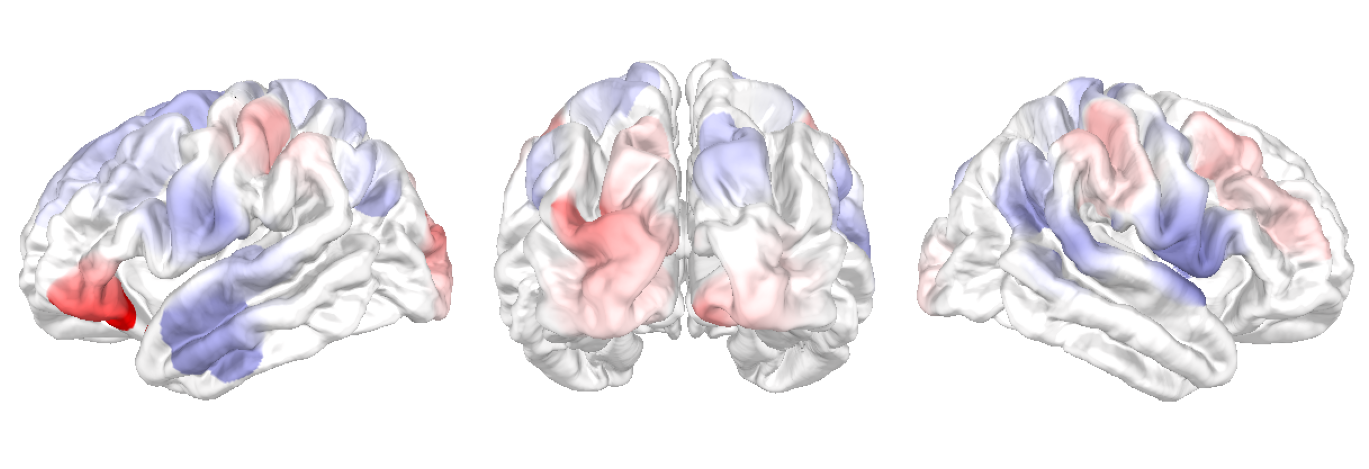

In [14]:
# Plot significant time x group interactions for hbdiff z-scores
from matplotlib import cm
from matplotlib.colors import ListedColormap
original_cmap = cm.get_cmap('RdBu_r', 256)
cmap = ListedColormap(original_cmap(np.linspace(0, 1, 256)))

# Brain plots by specific channels
df_final = significant_interactions
df_final['Channel'] = df_final['Channel'].str.upper()  # Convert to uppercase
df_final['Channel'] = df_final['Channel'].str.replace(r" (hbo|hbr|hbdiff)$", "", regex=True)  # Remove suffixes

# Load the raw data
fname = op.join(proc_path, f'201_1_001_long_hbo_DPZ_raw.fif')
use = mne.io.read_raw_fif(fname, preload=True)
use.load_data()

# Rename channels if necessary
new_ch_names = {}
seen_names = set()
for ch_name in use.info['ch_names']:
    new_name = ch_name.split(' ')[0]
    if new_name not in seen_names:
        new_ch_names[ch_name] = new_name
        seen_names.add(new_name)

use.rename_channels(new_ch_names)

# Pick channels for visualization
use.pick_channels(list(new_ch_names.values()))
info_of_interest = use.info

# Initialize highlight dictionary
highlight_values = np.zeros(len(info_of_interest['ch_names']))

# List of significant channels to check
highlight_channels = df_final['Channel'].tolist()

# Loop through each row in df_final and update highlight values for significant channels
for _, row in df_final.iterrows():
    ch_name = row['Channel']
    highlight_value = row['Estimate']
    ch_name_cleaned = ch_name.split()[0]  # Remove suffixes if any

    if ch_name_cleaned in info_of_interest['ch_names']:
        idx = info_of_interest['ch_names'].index(ch_name_cleaned)
        highlight_values[idx] = highlight_value
    else:
        print(f"Warning: Channel {ch_name_cleaned} not found in info_of_interest['ch_names']")

# Verify that the highlight_values array is being populated correctly
#print("Updated highlight values:")
#print(highlight_values)

# Check if all significant channels are in the plot
missing_channels = [ch for ch in highlight_channels if ch not in info_of_interest['ch_names']]
if missing_channels:
    print(f"The following significant channels are missing from the brain plot: {missing_channels}")
else:
    print("All significant channels are present in the brain plot.")

# Create an EvokedArray with the highlight values
evoked = mne.EvokedArray(highlight_values[:, np.newaxis], info_of_interest)

# Define a custom colormap from blue to white to red
cmap = LinearSegmentedColormap.from_list("blue_white_red", ["blue", "white", "red"], N=256)

# Create the source time course (STC) and highlight specific channels
stc = mne.stc_near_sensors(
    evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
    distance=0.02, project=True, picks=np.arange(len(info_of_interest['ch_names'])), subjects_dir=subjects_dir
)

# Set up the plotting (one figure with three views)
fig, axes = plt.subplots(1, 1, figsize=(15, 5))  # Only one plot for all three channels

# Set up the plotting for the current channels
brain = stc.plot(
    hemi='both', views=['lat', 'frontal', 'lat'],  # Plot 3 views: lateral, frontal, and left lateral
    cortex='low_contrast', time_viewer=False, show_traces=False,
    surface='pial', smoothing_steps=0, size=(1200, 400),
    clim=dict(kind='value', lims=[-4.0, 0, 4.0]),  # Ensure color scaling matches the colormap
    colormap=cmap,  # Use the manually defined colormap
    view_layout='horizontal',
    colorbar=(-4, 4), time_label='', background='w',
    brain_kwargs=dict(units='m'),
    add_data_kwargs=dict(colorbar_kwargs=dict(
        title_font_size=12, label_font_size=8, n_labels=3,
        title='Beta Estimates for Significant Channels')), subjects_dir=subjects_dir
)


brain.show_view('lat', hemi='lh', row=0, col=0)
brain.show_view(azimuth=270, elevation=90, row=0, col=1)
brain.show_view('lat', hemi='rh', row=0, col=2)

# Capture the plot as an image in memory
screenshot = brain.screenshot(time_viewer=False)
brain.close()                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

# Display the image in the composite figure
ax = axes
ax.imshow(screenshot)
ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(op.join(results_path, f'group_time_AV_hbdiff_composite_brain_plots_n9.png'))
plt.show()
plt.close(fig)



In [8]:
# Plot hbdiff z-scores for significant changes

from scipy.stats import ttest_rel
from matplotlib import cm
from matplotlib.colors import ListedColormap
import numpy as np
import os
import pandas as pd
import re
import mne
from scipy.stats import zscore
from matplotlib.colors import LinearSegmentedColormap

# Customize the RdBu colormap to ensure a deep red at the lower end
custom_cmap = cm.get_cmap('RdBu_r', 256)

conditions = ['A', 'AV', 'V']
groups = ['DPZ', 'PL']
chromas = ['hbdiff']

df_final = pd.read_csv(os.path.join(results_path, f'df_combined_final_cha_{output_suffix}.csv'))

for chroma in chromas:
    for condition in conditions:
        for group in groups:
            df_filtered = df_final.query(
                f"group == '{group}' and Chroma == '{chroma}' and Condition == '{condition}'"
            ).copy()
            subjects = df_filtered['subject'].unique()
            df_filtered['day'] = df_filtered['day'].astype(float)
            df_filtered['subject'] = df_filtered['subject'].astype(float)

            for subject in subjects:
                print(f"Processing Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}")

                # Filter data for Day 1 and Day 3
                df_day1 = df_filtered[(df_filtered['day'] == 1.0) & (df_filtered['subject'] == subject)]
                df_day3 = df_filtered[(df_filtered['day'] == 3.0) & (df_filtered['subject'] == subject)]

                # Clean channel names
                channels_day1 = df_day1['ch_name'].values
                channels_day3 = df_day3['ch_name'].values
                cleaned_channels_day1 = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in channels_day1]
                cleaned_channels_day3 = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in channels_day3]
                cleaned_info_ch_names = [re.sub(r" (hbo|hbr|hbdiff)$", "", ch) for ch in info['ch_names']]

                # Find common channels
                common_channels = np.intersect1d(cleaned_channels_day1, cleaned_channels_day3)
                channel_mapping = {ch: idx for idx, ch in enumerate(cleaned_info_ch_names)}
                all_indices = [channel_mapping[ch] for ch in common_channels if ch in channel_mapping]

                if len(all_indices) == 0:
                    print(f"No matching channels for Subject: {subject}. Skipping...")
                    continue

                # Prepare info
                info_all = mne.pick_info(info, sel=all_indices)

                # Map cleaned channel names back to original names
                original_channel_mapping_day1 = {re.sub(r" (hbo|hbr|hbdiff)$", "", ch): ch for ch in channels_day1}
                original_channel_mapping_day3 = {re.sub(r" (hbo|hbr|hbdiff)$", "", ch): ch for ch in channels_day3}
                mapped_channels_day1 = [original_channel_mapping_day1[ch] for ch in common_channels if ch in original_channel_mapping_day1]
                mapped_channels_day3 = [original_channel_mapping_day3[ch] for ch in common_channels if ch in original_channel_mapping_day3]

                # Get raw theta values
                theta_day1 = df_day1.set_index('ch_name').loc[mapped_channels_day1, 'theta'].values
                theta_day3 = df_day3.set_index('ch_name').loc[mapped_channels_day3, 'theta'].values

                # Paired t-test
                t_stat, p_values = ttest_rel(theta_day1, theta_day3)
                _, p_values_fdr = mne.stats.fdr_correction(p_values, alpha=0.05, method='indep')

                # Identify significant channels
                significant_channels = np.array(common_channels)[p_values_fdr < 0.05]
                if len(significant_channels) == 0:
                    print(f"No significant channels for Subject: {subject}. Skipping...")
                    continue

                # Compute Day 3 - Day 1 differences and z-score them
                theta_diff = theta_day3 - theta_day1
                z_diff = np.zeros_like(theta_diff)
                for i, ch in enumerate(common_channels):
                    if ch in significant_channels:
                        z_diff[i] = zscore(theta_diff)[i]

                # Ensure data matches the number of channels in info_all
                if z_diff.shape[0] != len(info_all['ch_names']):
                    print(f"Mismatch between z-scores and info channels for Subject: {subject}. Skipping...")
                    continue

                # Create the EvokedArray
                evoked_diff = mne.EvokedArray(data=np.expand_dims(z_diff, axis=1), info=info_all)

                # Plot the difference brain
                stc_diff = mne.stc_near_sensors(
                    evoked_diff, trans='fsaverage', subject='fsaverage', mode='weighted',
                    distance=0.03, project=True, picks=np.arange(len(info_all['ch_names'])),
                    subjects_dir=subjects_dir)

                brain_diff = stc_diff.plot(
                    hemi='both', views=['lateral', 'coronal', 'sagittal'], view_layout='horizontal', cortex='low_contrast',
                    time_viewer=False, show_traces=False, surface='pial', smoothing_steps=0,
                    size=(1200, 400), 
                    clim=dict(kind='value', lims=[-3.0, 0.0, 3.0]), 
                    colormap=custom_cmap,  # Use the custom colormap
                    time_label='', background='w',
                    brain_kwargs=dict(units='m'),
                    add_data_kwargs=dict(colorbar_kwargs=dict(
                        title_font_size=12, label_font_size=8, n_labels=3, title='   ')),
                    subjects_dir=subjects_dir)

                # Save the plot
                brain_diff.screenshot(time_viewer=False)
                brain_diff.save_image(os.path.join(results_path, f'{subject}_Change_{group}_{condition}_{chroma}_brain_plot.png'))
                brain_diff.close()

                print(f"Saved Day 3 - Day 1 brain plot for Subject: {subject}, Group: {group}, Condition: {condition}, Chroma: {chroma}.")


Processing Subject: 201, Group: DPZ, Condition: A, Chroma: hbdiff
No significant channels for Subject: 201. Skipping...
Processing Subject: 204, Group: DPZ, Condition: A, Chroma: hbdiff
No significant channels for Subject: 204. Skipping...
Processing Subject: 209, Group: DPZ, Condition: A, Chroma: hbdiff
No significant channels for Subject: 209. Skipping...
Processing Subject: 212, Group: DPZ, Condition: A, Chroma: hbdiff
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 6.1 mm
    236899 / 327684 non-zero vertices
Saved Day 3 - Day 1 brain plot for Subject: 212, Group: DPZ, Condition: A, Chroma: hbdiff.
Processing Subject: 203, Group: PL, Condition: A, Chroma: hbdiff
No significant channels for Subject: 203. Skipping...
Processing Subject: 205, Group: PL, Condition: A, Chroma: hbdiff
Projecting data from 84 sensors onto 327684 surface vertices: weighted mode
    Projecting sensor

In progress...

In [12]:
# Plot group x time for all conditions

from statsmodels.stats.multitest import multipletests

# Plot time x group interactions for hbdiff z-scores

# Load the data
z_diff_output_file = f"{results_path}/zscores_final_n9.csv"
df = pd.read_csv(z_diff_output_file)

# Filter data for HbO and all conditions
df = df[(df["chroma"] == "hbdiff")]

df_long = df.melt(
    id_vars=['subject', 'group', 'channel', 'condition', 'chroma'],  
    value_vars=['z_day1', 'z_day3'], 
    var_name='Time', 
    value_name='Z_Score'
)

# Convert "Time" to categorical (Day 1 = 1, Day 3 = 3)
df_long['Time'] = df_long['Time'].replace({'z_day1': 1, 'z_day3': 3})

# Ensure Time is categorical for modeling
df_long['Time'] = df_long['Time'].astype('category')
df_long["Group"] = df_long["group"].astype("category")
df_long["Group"] = df_long["Group"].cat.reorder_categories(["PL", "DPZ"], ordered=True)
df_long["Subject"] = df_long["subject"].astype("category")
df_long["Condition"] = df_long["condition"].astype("category")

# Store results
interaction_results = []

# Run models for each channel and each condition
for condition in df_long["condition"].unique():
    condition_df = df_long[df_long["condition"] == condition]

    for channel in condition_df["channel"].unique():
        channel_df = condition_df[condition_df["channel"] == channel]
        
        try:
            # Mixed-effects model with Time × Group interaction
            model = smf.mixedlm("Z_Score ~ Time * Group", channel_df, groups=channel_df["Subject"])
            result = model.fit(method="powell")

            # Extract p-values for interaction term
            interaction_pval = result.pvalues.get("Time[T.3]:Group[T.DPZ]", None)  # Adjust group label if needed
            
            # Store results
            if interaction_pval is not None:
                interaction_results.append([channel, condition, result.params["Time[T.3]:Group[T.DPZ]"], interaction_pval])
        
        except Exception as e:
            print(f"Error in channel {channel}: {e}")

# Convert to DataFrame
interaction_df = pd.DataFrame(interaction_results, columns=["Channel", "Condition", "Estimate", "P-Value"])

# Apply FDR correction across all conditions and channels
if not interaction_df.empty:
    interaction_df["FDR-Corrected P-Value"] = multipletests(interaction_df["P-Value"], alpha=0.05, method="fdr_bh")[1]
    interaction_df["Significant"] = interaction_df["FDR-Corrected P-Value"] < 0.05

    # Filter only significant results
    significant_interactions = interaction_df[interaction_df["Significant"]]

    # Save the significant results to a CSV file for easy access
    significant_interactions.to_csv(f"{results_path}/significant_time_group_interactions_fdr.csv", index=False)

    # Print the results in a format that's easy to copy
    print("\nSignificant Time × Group interactions were found in the following channels:\n")
    print(significant_interactions.to_string(index=False))

else:
    print("No significant interactions after FDR correction.")

# Plot significant time x group interactions for hbdiff z-scores

# Brain plots by specific channels
df_final = significant_interactions
df_final['Channel'] = df_final['Channel'].str.upper()  # Convert to uppercase
df_final['Channel'] = df_final['Channel'].str.replace(r" (hbo|hbr|hbdiff)$", "", regex=True)  # Remove suffixes

# Load the raw data
fname = op.join(proc_path, f'201_1_001_long_hbo_DPZ_raw.fif')
use = mne.io.read_raw_fif(fname, preload=True)
use.load_data()

# Rename channels if necessary
new_ch_names = {}
seen_names = set()
for ch_name in use.info['ch_names']:
    new_name = ch_name.split(' ')[0]
    if new_name not in seen_names:
        new_ch_names[ch_name] = new_name
        seen_names.add(new_name)

use.rename_channels(new_ch_names)

# Pick channels for visualization
use.pick_channels(list(new_ch_names.values()))
info_of_interest = use.info

# Loop through each condition and generate a plot
for condition in ['A']:

    # Filter for the current condition
    condition_df = df_final[df_final['Condition'] == condition]

    # Initialize highlight dictionary
    highlight_values = np.zeros(len(info_of_interest['ch_names']))

    # List of significant channels to check
    highlight_channels = condition_df['Channel'].tolist()

    # Loop through each row in df_final and update highlight values for significant channels
    for _, row in condition_df.iterrows():
        ch_name = row['Channel']
        highlight_value = row['Estimate']
        ch_name_cleaned = ch_name.split()[0]  # Remove suffixes if any

        if ch_name_cleaned in info_of_interest['ch_names']:
            idx = info_of_interest['ch_names'].index(ch_name_cleaned)
            highlight_values[idx] = highlight_value
        else:
            print(f"Warning: Channel {ch_name_cleaned} not found in info_of_interest['ch_names']")

    # Check if all significant channels are in the plot
    missing_channels = [ch for ch in highlight_channels if ch not in info_of_interest['ch_names']]
    if missing_channels:
        print(f"The following significant channels are missing from the brain plot: {missing_channels}")
    else:
        print("All significant channels are present in the brain plot.")

    # Create an EvokedArray with the highlight values
    evoked = mne.EvokedArray(highlight_values[:, np.newaxis], info_of_interest)

    # Define a custom colormap from blue to white to red
    cmap = LinearSegmentedColormap.from_list("blue_white_red", ["blue", "white", "red"], N=256)

    # Create the source time course (STC) and highlight specific channels
    stc = mne.stc_near_sensors(
        evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
        distance=0.02, project=True, picks=np.arange(len(info_of_interest['ch_names'])), subjects_dir=subjects_dir
    )

    # Set up the plotting (one figure with three views)
    fig, axes = plt.subplots(1, 1, figsize=(15, 5))  # Only one plot for all three channels

    # Set up the plotting for the current channels
    brain = stc.plot(
        hemi='both', views=['lat', 'frontal', 'lat'],  # Plot 3 views: lateral, frontal, and left lateral
        cortex='low_contrast', time_viewer=False, show_traces=False,
        surface='pial', smoothing_steps=0, size=(1200, 400),
        clim=dict(kind='value', lims=[-4.0, 0, 4.0]),  # Ensure color scaling matches the colormap
        colormap=cmap,  # Use the manually defined colormap
        view_layout='horizontal',
        colorbar=(-4, 4), time_label='', background='w',
        brain_kwargs=dict(units='m'),
        add_data_kwargs=dict(colorbar_kwargs=dict(
            title_font_size=12, label_font_size=8, n_labels=3,
            title='Beta Estimates for Significant Channels')), subjects_dir=subjects_dir
    )

    brain.show_view('lat', hemi='lh', row=0, col=0)
    brain.show_view(azimuth=270, elevation=90, row=0, col=1)
    brain.show_view('lat', hemi='rh', row=0, col=2)

    # Capture the plot as an image in memory
    screenshot = brain.screenshot(time_viewer=False)
    brain.close()

    # Display the image in the composite figure
    ax = axes
    ax.imshow(screenshot)
    ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
#    plt.savefig(op.join(results_path, f'group_time_{condition}_hbdiff_composite_brain_plots.png'))
#    plt.show()
    plt.close(fig)


ValueError: items in new_categories are not the same as in old categories

In [ ]:
import pandas as pd
import os
import numpy as np
import mne
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.stats.multitest import multipletests

# Load significant interaction results
significant_results_file = "significant_time_group_interactions_fdr.csv"
significant_interactions = pd.read_csv(significant_results_file)

# Load the full dataset
z_diff_output_file = f"{results_path}/zscores_final_n9.csv"
df = pd.read_csv(z_diff_output_file)

# Filter for HbDiff (hbdiff) and Condition A only
df = df[(df["chroma"] == "hbdiff") & (df["condition"] == "A")]

# Convert to long format
df_long = df.melt(
    id_vars=['subject', 'group', 'channel', 'condition', 'chroma'],  
    value_vars=['z_day1', 'z_day3'], 
    var_name='Time', 
    value_name='Z_Score'
)

# Convert "Time" to categorical (Day 1 = 1, Day 3 = 3)
df_long['Time'] = df_long['Time'].replace({'z_day1': 1, 'z_day3': 3}).astype('category')

# Ensure categorical variables
df_long["Group"] = df_long["group"].astype("category")
df_long["Group"] = df_long["Group"].cat.reorder_categories(["PL", "DPZ"], ordered=True)
df_long["Subject"] = df_long["subject"].astype("category")

# Filter only significant channels
significant_channels = significant_interactions["Channel"].unique()
df_long = df_long[df_long["channel"].isin(significant_channels)]

# Load MNE EEG layout with expected channel locations
fname = os.path.join(proc_path, "201_1_001_long_hbo_DPZ_raw.fif")
raw = mne.io.read_raw_fif(fname, preload=True)
raw.load_data()

# Rename channels if necessary
new_ch_names = {ch: ch.split()[0] for ch in raw.info["ch_names"]}
raw.rename_channels(new_ch_names)

# Ensure channels match between raw data and our results
raw.pick_channels(list(new_ch_names.values()))
info = raw.info

# Define a custom colormap from blue to white to red
cmap = LinearSegmentedColormap.from_list("blue_white_red", ["blue", "white", "red"], N=256)

# Create brain plots for each group
for group in ["PL", "DPZ"]:
    group_df = df_long[df_long["Group"] == group]
    
    # Compute mean Z_Score difference (Day 3 - Day 1) for each significant channel
    mean_z_diff = group_df.pivot_table(index="channel", columns="Time", values="Z_Score", aggfunc="mean")
    mean_z_diff["ZDiff"] = mean_z_diff[3] - mean_z_diff[1]  # Day 3 minus Day 1
    
    # Initialize highlight values for each channel
    highlight_values = np.zeros(len(info["ch_names"]))

    # Loop through significant channels and map them to MNE sensor layout
    for ch_name in mean_z_diff.index:
        if ch_name in info["ch_names"]:
            idx = info["ch_names"].index(ch_name)
            highlight_values[idx] = mean_z_diff.loc[ch_name, "ZDiff"]
        else:
            print(f"Warning: Channel {ch_name} not found in EEG layout.")

    # Create an EvokedArray with highlight values
    evoked = mne.EvokedArray(highlight_values[:, np.newaxis], info)

    # Generate topographic brain plot
    fig, ax = plt.subplots(figsize=(8, 6))
    im, cn = mne.viz.plot_topomap(
        highlight_values,
        evoked.info,
        axes=ax,
        cmap=cmap,
        show=False,
        vmin=-np.max(np.abs(highlight_values)),
        vmax=np.max(np.abs(highlight_values))
    )

    # Add colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("ZDiff (Day 3 - Day 1)", fontsize=12)

    # Title and labels
    ax.set_title(f"Brain Plot: HbDiff Z-Scores ({group} Group, Condition A)", fontsize=14)

    # Save figure
    plot_filename = f"{results_path}/brain_plot_hbdiff_{group}_ConditionA.png"
    plt.savefig(plot_filename, dpi=300)
    plt.close()

    print(f"Saved brain plot: {plot_filename}")

print("\nBrain plots saved for significant HbDiff ZDiff scores in Condition A.")


In [ ]:
# Plot sensors of interest

import mne
import matplotlib.pyplot as plt
import os.path as op

# Use the info from your existing data
proc_path = '../../processed'
fname = op.join(proc_path, f'205_1_001_long_hbo_final_raw.fif')
use = mne.io.read_raw_fif(fname, preload=True)
use.load_data()
info = use.copy().info

# Specify the names of the sensors you want to plot
selected_sensors = ['S19_D6 hbo', 'S25_D14 hbo', 'S19_D4 hbo']
#selected_sensors = ['S14_D22 hbo', 'S21_D8 hbo', 'S3_D3', 'S18_D26 hbo', 'S23_D10 hbo']
# fusiform/ITG/MTG, STG/MTG, Broca's/premotor, V3, fusiform/V3
#selected_sensors = ['S10_D20 hbo', 'S3_D6 hbo', 'S8_D20 hbo'] # STG/MTG, Subcentral area/premotor x2
valid_sensors = [sensor for sensor in selected_sensors if sensor in info['ch_names']]

if not valid_sensors:
    print("No valid sensors selected for plotting.")
else:
    # Increase the font size for sensor names
    plt.rcParams.update({'font.size': 20})  # Set the desired font size

    # Pick only the selected channels
    info_picked = mne.pick_info(info, mne.pick_channels(info['ch_names'], valid_sensors))
    info_picked.rename_channels({ch: '  ' + ch for ch in info_picked['ch_names']})

    # Plot the sensors manually with blue circles
    fig = mne.viz.plot_sensors(info_picked, kind='topomap', show_names=False, pointsize=800, linewidth=0)

    plt.show()



In [ ]:
# Plot some waveforms

import mne
import os.path as op
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load subject group mapping
#subject_group_mapping = pd.read_csv('../../subject_group_mapping.csv')
#subject_group_mapping['Subject'] = subject_group_mapping['Subject'].astype(str).str.strip().str.split('.').str[0]
#subject_to_group = dict(zip(subject_group_mapping['Subject'], subject_group_mapping['Group']))

# Ensure all subjects are in string format without decimals
subjects = subject_group_mapping['Subject'].tolist()

# Define the subjects in the 'trained' group
trained_subjects = [subject for subject in subjects if subject_to_group[subject] == 'trained']

# Specify the channel of interest
channel_of_interest = 'S21_D10'
condition = 'AV'

# Initialize the dictionaries to store evoked data for averaging and plotting
evoked_dict_day1 = {'HbO': [], 'HbR': []}
evoked_dict_day3 = {'HbO': [], 'HbR': []}

# Loop over subjects and load their evoked data
for subject in trained_subjects:
    for day in ['1', '3']:
        # Define the filename
        fname = op.join(proc_path, f'{subject}_{day}_final-ave.fif')
        
        # Load the evoked data
        evokeds = mne.read_evokeds(fname, condition=condition, baseline=(None, 0), verbose=False)
                
        # Pick the HbO and HbR data for the channel of interest
        evoked_hbo = evokeds.copy().pick([f'{channel_of_interest} hbo'])
        evoked_hbr = evokeds.copy().pick([f'{channel_of_interest} hbr'])
        
        evoked_hbo.rename_channels(lambda x: x[:-4])
        evoked_hbr.rename_channels(lambda x: x[:-4])
        
        # Check if both HbO and HbR data exist for this subject and day
        if len(evoked_hbo.ch_names) == 1 and len(evoked_hbr.ch_names) == 1:
            # Store in the appropriate evoked dictionary
            if day == '1':
                evoked_dict_day1['HbO'].append(evoked_hbo)
                evoked_dict_day1['HbR'].append(evoked_hbr)
            elif day == '3':
                evoked_dict_day3['HbO'].append(evoked_hbo)
                evoked_dict_day3['HbR'].append(evoked_hbr)

# Compute grand average for Day 1 and Day 3
grand_avg_day1_hbo = mne.grand_average(evoked_dict_day1['HbO'])
grand_avg_day1_hbr = mne.grand_average(evoked_dict_day1['HbR'])
grand_avg_day3_hbo = mne.grand_average(evoked_dict_day3['HbO'])
grand_avg_day3_hbr = mne.grand_average(evoked_dict_day3['HbR'])

# Prepare the grand average dictionary for plotting
grand_avg_dict_day1 = {'HbO': grand_avg_day1_hbo, 'HbR': grand_avg_day1_hbr}
grand_avg_dict_day3 = {'HbO': grand_avg_day3_hbo, 'HbR': grand_avg_day3_hbr}

# Define the colors and styles
color_dict_day1 = {'HbO': 'red', 'HbR': 'blue'}
color_dict_day3 = {'HbO': 'red', 'HbR': 'blue'}
styles_dict_day1 = {'HbO': {'linestyle': '--'}, 'HbR': {'linestyle': '--'}}
styles_dict_day3 = {'HbO': {'linestyle': '-'}, 'HbR': {'linestyle': '-'}}

# Plot for Day 1 using the grand average
mne.viz.plot_compare_evokeds(
    grand_avg_dict_day1,
    ci=0.95, colors=color_dict_day1, styles=styles_dict_day1,
    title=f'{channel_of_interest} ({condition} Condition) - Day 1', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.10, 0.10))  # This line sets the y-axis limits
)

# Plot for Day 3 using the grand average
mne.viz.plot_compare_evokeds(
    grand_avg_dict_day3,
    ci=0.95, colors=color_dict_day3, styles=styles_dict_day3,
    title=f'{channel_of_interest} ({condition} Condition) - Day 3', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.10, 0.10))  # This line sets the y-axis limits
)

# Initialize the dictionaries to store evoked data for plotting
evoked_dict_day1 = {'HbO': [], 'HbR': []}
evoked_dict_day3 = {'HbO': [], 'HbR': []}

# Loop over subjects and load their evoked data
for subject in trained_subjects:
    for day in ['1', '3']:
        # Define the filename
        fname = op.join(proc_path, f'{subject}_{day}_final-ave.fif')
        
        # Load the evoked data
        evokeds = mne.read_evokeds(fname, condition=condition, baseline=(None, 0), verbose=False)
                
        # Pick the HbO and HbR data for the channel of interest
        evoked_hbo = evokeds.copy().pick([f'{channel_of_interest} hbo'])
        evoked_hbr = evokeds.copy().pick([f'{channel_of_interest} hbr'])
        
        evoked_hbo.rename_channels(lambda x: x[:-4])
        evoked_hbr.rename_channels(lambda x: x[:-4])
        
        # Check if both HbO and HbR data exist for this subject and day
        if len(evoked_hbo.ch_names) == 1 and len(evoked_hbr.ch_names) == 1:
            # Store in the appropriate evoked dictionary
            if day == '1':
                evoked_dict_day1['HbO'].append(evoked_hbo)
                evoked_dict_day1['HbR'].append(evoked_hbr)
            elif day == '3':
                evoked_dict_day3['HbO'].append(evoked_hbo)
                evoked_dict_day3['HbR'].append(evoked_hbr)

# Check if all participants were included
expected_subjects = len(trained_subjects)
actual_subjects_day1 = len(evoked_dict_day1['HbO'])  # Same number for HbO and HbR
actual_subjects_day3 = len(evoked_dict_day3['HbO'])  # Same number for HbO and HbR

if actual_subjects_day1 != expected_subjects:
    print(f"Warning: Only {actual_subjects_day1} out of {expected_subjects} subjects were included in the Day 1 analysis.")
else:
    print("All participants were included in the Day 1 analysis.")

if actual_subjects_day3 != expected_subjects:
    print(f"Warning: Only {actual_subjects_day3} out of {expected_subjects} subjects were included in the Day 3 analysis.")
else:
    print("All participants were included in the Day 3 analysis.")

# Define the colors and styles
color_dict_day1 = {'HbO': 'red', 'HbR': 'blue'}
color_dict_day3 = {'HbO': 'red', 'HbR': 'blue'}
styles_dict_day1 = {'HbO': {'linestyle': '--'}, 'HbR': {'linestyle': '--'}}
styles_dict_day3 = {'HbO': {'linestyle': '-'}, 'HbR': {'linestyle': '-'}}

# Plot for Day 1 using the individual evoked responses
mne.viz.plot_compare_evokeds(
    {'HbO': evoked_dict_day1['HbO'], 'HbR': evoked_dict_day1['HbR']},
    ci=0.95, colors=color_dict_day1, styles=styles_dict_day1,
    title=f'{channel_of_interest} ({condition} Condition) - Day 1', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.20, 0.20))  # This line sets the y-axis limits
)

# Plot for Day 3 using the individual evoked responses
mne.viz.plot_compare_evokeds(
    {'HbO': evoked_dict_day3['HbO'], 'HbR': evoked_dict_day3['HbR']},
    ci=0.95, colors=color_dict_day3, styles=styles_dict_day3,
    title=f'{channel_of_interest} ({condition} Condition) - Day 3', show=True,
    truncate_xaxis=(-2, 15),  # This line sets the x-axis limits
    ylim=dict(hbo=(-0.20, 0.20))  # This line sets the y-axis limits
)


In [ ]:
# Plot topographic maps of significant models

for group in groups:
    df_r2 = pd.read_csv(op.join(results_path, f'{group}_fnirs-behavior-models_{group}.csv'))
    df_filtered = df_r2[(df_r2['P-value Corrected'] < 0.05)]
    ch_names = df_filtered['Channel'].values 
    info = use.copy().pick_types(fnirs='hbo', exclude=())
    info_picked = info.pick_channels(ch_names)
    fig = mne.viz.plot_sensors(info_picked.info, kind='topomap', show_names=True, pointsize=100, linewidth=0]
    plt.savefig(op.join(results_path, f'{group}_sig-p-corr_topomap.png'))
    plt.show()
    plt.close(fig)
 

In [ ]:
import pandas as pd
import os
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
z_diff_output_file = f"{results_path}/zscores_final_n9.csv"
merged_df = pd.read_csv(z_diff_output_file)

# Define ROI landmarks
selected_landmarks = [
    "22 - Superior Temporal Gyrus",
    "21 - Middle Temporal gyrus",
    "42 - Primary and Auditory Association Cortex",
    "17 - Primary Visual Cortex (V1)",
    "18 - Visual Association Cortex (V2)",
    "19 - V3"
]

# Filter data for selected landmarks
filtered_df = merged_df[merged_df["Landmark"].isin(selected_landmarks)]

# Aggregate z-scores per landmark
avg_zscores_df = filtered_df.groupby(["Landmark", "group", "subject", "condition"])[["z_day1", "z_day3"]].mean().reset_index()

# Reshape data for mixed-effects model analysis
df_long = avg_zscores_df.melt(
    id_vars=['Landmark', 'subject', 'group', 'condition'],  
    value_vars=['z_day1', 'z_day3'], 
    var_name='Time', 
    value_name='Z_Score'
)

# Convert "Time" to categorical (Day 1 = 1, Day 3 = 3)
df_long['Time'] = df_long['Time'].replace({'z_day1': 1, 'z_day3': 3}).astype('category')

# Ensure categorical variables for modeling
df_long["Group"] = df_long["group"].astype("category")
df_long["Group"] = df_long["Group"].cat.reorder_categories(["PL", "DPZ"], ordered=True)
df_long["Subject"] = df_long["subject"].astype("category")
df_long["Condition"] = df_long["condition"].astype("category")

# Store results
interaction_results = []

# Run models for each landmark and condition
for condition in df_long["Condition"].unique():
    condition_df = df_long[df_long["Condition"] == condition]

    for landmark in condition_df["Landmark"].unique():
        landmark_df = condition_df[condition_df["Landmark"] == landmark]
        
        try:
            # Mixed-effects model with Time × Group interaction
            model = smf.mixedlm("Z_Score ~ Time * Group", landmark_df, groups=landmark_df["Subject"])
            result = model.fit(method="powell")

            # Extract p-values for interaction term
            interaction_pval = result.pvalues.get("Time[T.3]:Group[T.DPZ]", None)
            
            # Store results
            if interaction_pval is not None:
                interaction_results.append([landmark, condition, result.params["Time[T.3]:Group[T.DPZ]"], interaction_pval])
        
        except Exception as e:
            print(f"Error in landmark {landmark}: {e}")

# Convert to DataFrame
interaction_df = pd.DataFrame(interaction_results, columns=["Landmark", "Condition", "Estimate", "P-Value"])

# Apply FDR correction
if not interaction_df.empty:
    interaction_df["FDR-Corrected P-Value"] = multipletests(interaction_df["P-Value"], alpha=0.05, method="fdr_bh")[1]
    interaction_df["Significant"] = interaction_df["FDR-Corrected P-Value"] < 0.05

    # Filter only significant results
    significant_interactions = interaction_df[interaction_df["Significant"]]

    # Display results
    print("\nSignificant Time × Group interactions were found in the following landmarks:\n")
    print(significant_interactions.to_string(index=False))

else:
    print("No significant interactions after FDR correction.")

# Save results
interaction_df.to_csv(f"{results_path}/interaction_results_n9.csv", index=False)

# ---- PLOT SIGNIFICANT RESULTS ----
if not significant_interactions.empty:
    for _, row in significant_interactions.iterrows():
        landmark = row["Landmark"]
        condition = row["Condition"]

        # Filter df_long for the specific landmark and condition
        plot_df = df_long[(df_long["Landmark"] == landmark) & (df_long["Condition"] == condition)]

        # Individual subject trajectories
        plt.figure(figsize=(8, 6))
        sns.lineplot(
            data=plot_df,
            x="Time",
            y="Z_Score",
            hue="Group",
            style="Group",
            markers=["o", "s"],
            dashes=False,
            estimator=None,  # Show individual trajectories
            units="Subject",
            alpha=0.7,
            palette={"PL": "black", "DPZ": "red"}
        )

        # Customize the plot
        plt.xlabel("Time (Day)")
        plt.ylabel("Z-Score Activity")
        plt.title(f"Z-Score Changes: {landmark} ({condition})")
        plt.xticks(ticks=[1, 3], labels=["Day 1", "Day 3"])
        plt.legend(title="Group")
        plt.grid(True, linestyle="--", alpha=0.5)
        plt.tight_layout()
        plt.savefig(f"{results_path}/plot_{landmark.replace(' ', '_')}_{condition}_trajectories.png")
        plt.show()

        # Mean and 95% CI plot
        plt.figure(figsize=(8, 6))
        sns.pointplot(
            data=plot_df,
            x="Time",
            y="Z_Score",
            hue="Group",
            dodge=True,
            ci=95,
            markers=["o", "s"],
            linestyles=["-", "--"],
            palette={"PL": "black", "DPZ": "red"}
        )

        # Customize the plot
        plt.xlabel("Time (Day)")
        plt.ylabel("Mean Z-Score Activity")
        plt.title(f"Mean Z-Score Changes: {landmark} ({condition})")
        plt.xticks(ticks=[0, 1], labels=["Day 1", "Day 3"])
        plt.legend(title="Group")
        plt.grid(True, linestyle="-", alpha=0.5)
        plt.tight_layout()
        plt.savefig(f"{results_path}/plot_{landmark.replace(' ', '_')}_{condition}_means.png")
        plt.show()

print("\nPlots saved for significant interactions.")


In [ ]:
# Convert to DataFrame for easier comparison
specificity_df = pd.read_csv(f"{results_path}/specificity_with_optodes.csv")
hemisphere_df_corrected = pd.read_csv(f"{results_path}/optodes_hemi.csv")

# Standardize 'ch_name' in specificity data (remove leading 0s, strip spaces, remove 'hbo'/'hbr')
specificity_df["ch_name"] = specificity_df["ch_name"].str.strip().str.replace(r" hbo| hbr", "", regex=True)
specificity_df["ch_name"] = specificity_df["ch_name"].str.replace(r"S0", "S", regex=True)  # Remove leading 0s

# Merge hemisphere data with specificity data based on corrected channel names
merged_hemisphere_specificity_df = hemisphere_df_corrected.merge(specificity_df, left_on="Channel", right_on="ch_name", how="left")

save_path = f"{results_path}/hemi_specificity.csv"
merged_hemisphere_specificity_df.to_csv(save_path, index=False)

In [ ]:
# time x group interactions separated by hemisphere

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

# Load Z-score dataset and merged hemisphere data
z_diff_output_file = f"{results_path}/zscores_final_n9.csv"
df_long = pd.read_csv(z_diff_output_file)

df_long = df_long.dropna(subset=["Hemisphere"])
df_long = df_long[df_long["Specificity"] > 0.10]
df_long = df_long[df_long["Landmark"] != "Brain_Outside"]

df_long = df_long.melt(
    id_vars=['group', 'subject', 'condition', 'channel', 'Hemisphere', 'Landmark'],
    value_vars=['z_day1', 'z_day3'],
    var_name='Time',
    value_name='Z_Score'
)

# Convert "Time" to categorical (Day 1 = 1, Day 3 = 3)
df_long['Time'] = df_long['Time'].replace({'z_day1': 1, 'z_day3': 3}).astype('category')
df_long["group"] = df_long["group"].astype("category")
df_long["group"] = df_long["group"].cat.reorder_categories(["PL", "DPZ"], ordered=True)
#df_long = df_long[df_long["condition"] == "A"]

#print(df_long.head()) 

# Store results separately for each hemisphere
interaction_results = []

# Run models separately for Left and Right hemispheres
for hemisphere in ["Left", "Right"]:
    hemi_df = df_long[df_long["Hemisphere"] == hemisphere]

    for condition in hemi_df["condition"].unique():
        condition_df = hemi_df[hemi_df["condition"] == condition]

        for landmark in condition_df["Landmark"].unique():
            landmark_df = condition_df[condition_df["Landmark"] == landmark]
            landmark_df_avg = landmark_df.groupby(['subject', 'group', 'Time']).agg({'Z_Score': 'mean'}).reset_index()
            landmark_df_avg = landmark_df_avg.dropna(subset=['Z_Score'])
            expected_rows = 9 * 2  # 9 subjects × 2 timepoints
            actual_rows = len(landmark_df_avg)
            unique_subjects = landmark_df_avg['subject'].nunique()
            group_counts = landmark_df_avg.groupby('group')['subject'].nunique().to_dict()
            print(f"[{landmark} | {hemisphere} | {condition}] Rows: {actual_rows} | Subjects: {unique_subjects} | Group Ns: {group_counts}")
            if landmark_df_avg["Time"].nunique() < 2 or landmark_df_avg["group"].nunique() < 2:
                print(f"⚠️ Skipping {landmark} ({hemisphere}, {condition}) — insufficient Time or Group levels.")

            try:
                # Mixed-effects model with Time × Group interaction
                model = smf.mixedlm("Z_Score ~ Time * group", landmark_df_avg, groups=landmark_df_avg["subject"])
                result = model.fit(method="powell", maxiter=200)

                # Store results
                interaction_term = [term for term in result.params.index if "Time" in term and "group" in term]
                if "Time[T.3]:group[T.DPZ]" in result.params:
                    beta = result.params["Time[T.3]:group[T.DPZ]"]
                    interaction_pval = result.pvalues["Time[T.3]:group[T.DPZ]"]
                    interaction_results.append([landmark, condition, hemisphere, beta, interaction_pval])
                else:
                    print(f"Interaction term missing for {landmark} ({hemisphere}, {condition})")
                    
            except IndexError as e:
                print(f"IndexError in landmark {landmark} ({hemisphere}, {condition}): {e}")
                print(f"> landmark_df_avg shape: {landmark_df_avg.shape}")
                print("> First few rows of landmark_df_avg:")
                print(landmark_df_avg.head())

            except Exception as e:
                print(f"Error in landmark {landmark} ({hemisphere} Hemisphere): {e}")

# Convert to DataFrame
interaction_df = pd.DataFrame(interaction_results, columns=["Landmark", "condition", "Hemisphere", "Estimate", "P-Value"])

# Apply FDR correction per condition
interaction_df["FDR-Corrected P-Value"] = np.nan
interaction_df["Significant"] = False

for condition in interaction_df["condition"].unique():
    condition_mask = interaction_df["condition"] == condition
    pvals = interaction_df.loc[condition_mask, "P-Value"].values

    if len(pvals) > 0:
        _, fdr_corrected, _, _ = multipletests(pvals, alpha=0.05, method="fdr_bh")
        interaction_df.loc[condition_mask, "FDR-Corrected P-Value"] = fdr_corrected
        interaction_df.loc[condition_mask, "Significant"] = fdr_corrected < 0.05

# Save results
interaction_results_file = f"{results_path}/time_results_by_hemisphere.csv"
interaction_df.to_csv(interaction_results_file, index=False)

print(f"Analysis completed. Results saved: {interaction_results_file}")

## May 11, 2025 I started to mess with this code to analyze by landmark correctly. Not done yet!

[18 - Visual Association Cortex (V2) | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[19 - V3 | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[17 - Primary Visual Cortex (V1) | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[21 - Middle Temporal gyrus | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[22 - Superior Temporal Gyrus | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[48 - Retrosubicular area | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[20 - Inferior Temporal gyrus | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[38 - Temporopolar area | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[43 - Subcentral area | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[42 - Primary and Auditory Association Cortex | Left | A] Rows: 16 | Subjects: 8 | Group Ns: {'PL': 4, 'DPZ': 4}
[45 - pars triangularis Broca's area | Left |

Opening raw data file ../../processed_DPZ/212_3_001_long_hbo_DPZ_raw.fif...
    Range : 0 ... 3935 =      0.000 ...   818.480 secs
Ready.
Reading 0 ... 3935  =      0.000 ...   818.480 secs...
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Projecting data from 16 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 9.5 mm
    35650 / 327684 non-zero vertices


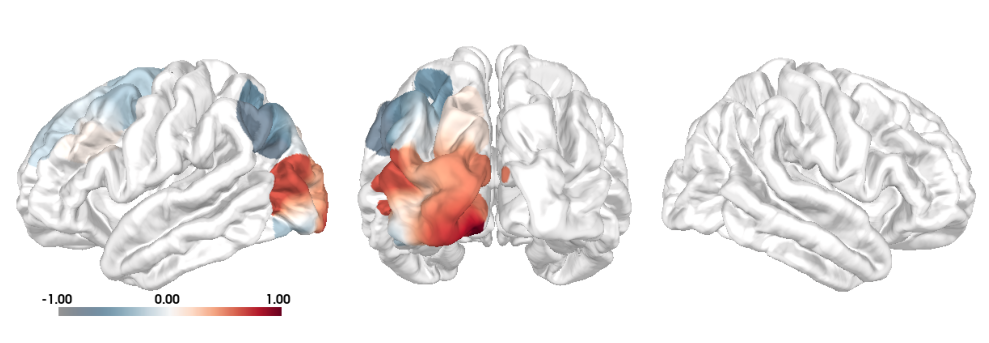

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Projecting data from 16 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 9.5 mm
    35650 / 327684 non-zero vertices


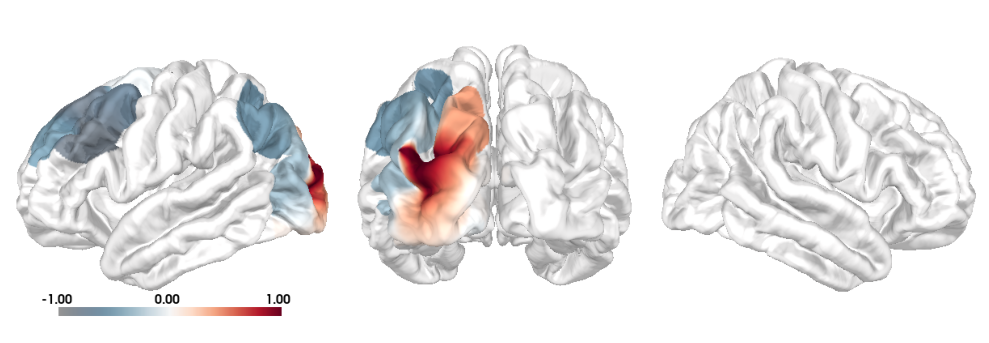

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Projecting data from 16 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 9.5 mm
    35650 / 327684 non-zero vertices


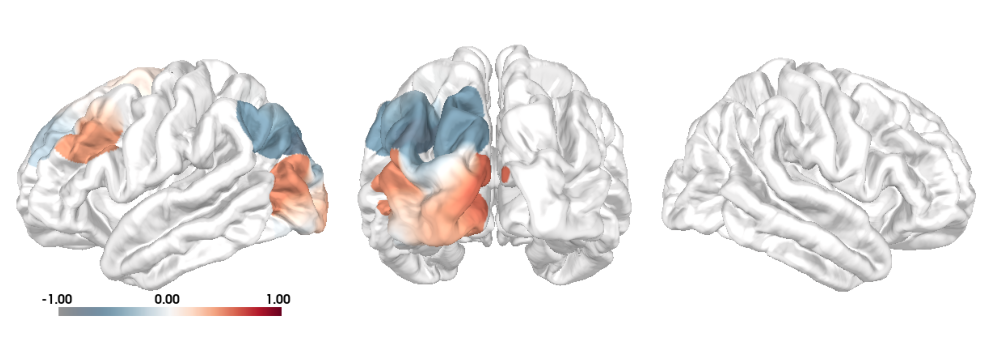

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Projecting data from 16 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 9.5 mm
    35650 / 327684 non-zero vertices


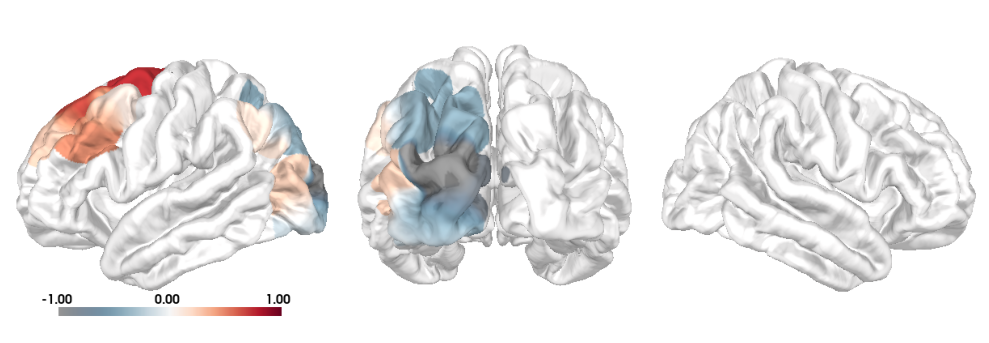

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Projecting data from 16 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 9.5 mm
    35650 / 327684 non-zero vertices


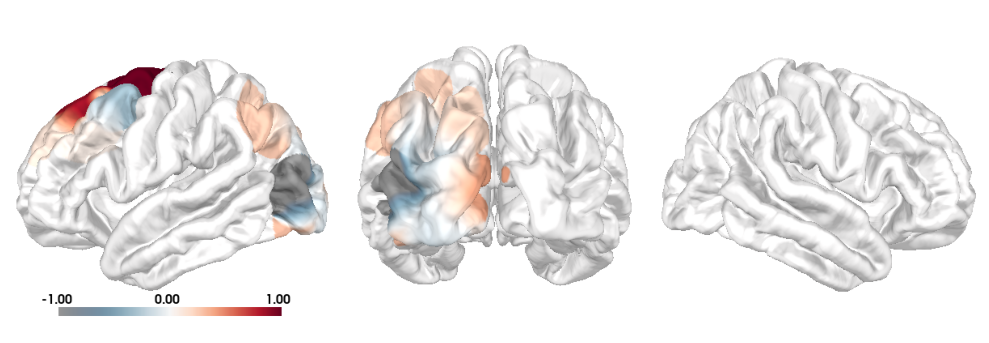

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Projecting data from 16 sensors onto 327684 surface vertices: weighted mode
    Projecting sensors onto surface
    Minimum projected intra-sensor distance: 9.5 mm
    35650 / 327684 non-zero vertices


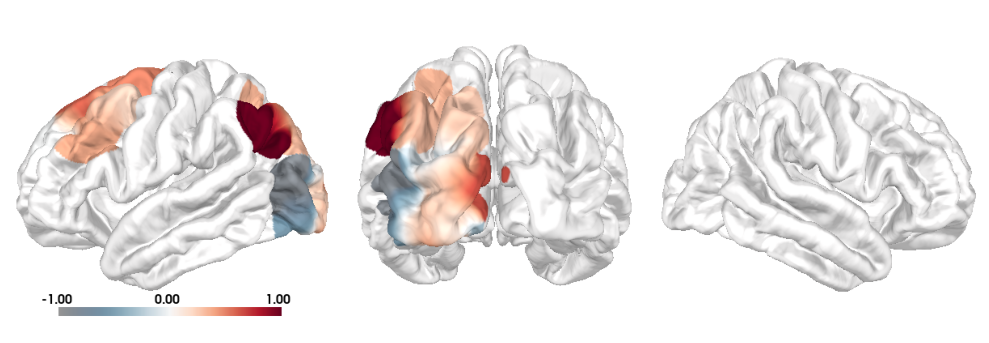

In [11]:
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
subjects_dir = '../../subjects_DPZ'

# Load dataset and filter for hbdiff chroma
df = pd.read_csv(f"{results_path}/zscores_final_n9.csv")
df = df[df["chroma"] == "hbo"]

# Standardize dataset channel names
df["channel"] = df["channel"].str.upper().str.replace(" HBO", "").str.replace(" HBR", "")

# Define the selected channels
selected_channels = [
    "S2_D1", "S2_D3", "S4_D1", "S4_D3", "S4_D5",
    "S15_D11", "S25_D11", "S25_D12", "S25_D13", "S25_D14",
    "S15_D11", "S23_D12", "S24_D11", "S25_D11", "S25_D12",
    "S25_D13", "S25_D14", "S26_D12", "S26_D13", "S15_D11",
    "S23_D12", "S24_D10", "S24_D11", "S24_D9", "S25_D11",
    "S25_D12", "S25_D13", "S26_D12", "S26_D13"
]

# Remove duplicates
selected_channels = list(set(selected_channels))

# Filter data for selected channels and compute mean z_diff per group per channel
df_filtered = df[df["channel"].isin(selected_channels)]
df_grouped = df_filtered.groupby(["group", "channel", "condition"])["z_diff"].mean().reset_index()

# Load the raw data file to get channel positions
raw_file_path = f"{proc_path}/212_3_001_long_hbo_DPZ_raw.fif"
raw = mne.io.read_raw_fif(raw_file_path, preload=True)
raw.load_data()

# Rename channels to ensure uniqueness
existing_ch_names = raw.info['ch_names']
new_ch_names = {}

for ch in existing_ch_names:
    base_name = ch.split(' ')[0]  # Remove spaces or suffixes
    if base_name not in new_ch_names.values():
        new_ch_names[ch] = base_name  # Assign unique names

# Rename channels safely
raw.rename_channels(new_ch_names)

# Iterate through each group separately and generate plots
for group in df_grouped["group"].unique():
    group_df = df_grouped[df_grouped["group"] == group]
    for condition in df_grouped["condition"].unique():
        group_df2 = group_df[group_df["condition"] == condition]

        # Ensure only selected channels are picked
        raw.pick_channels(selected_channels)

        # Prepare data for brain plots
        highlight_values = np.zeros(len(raw.ch_names))

        # Assign z_diff values to the corresponding channels
        for _, row in group_df2.iterrows():
            ch_name = row["channel"]
            if ch_name in raw.ch_names:
                idx = raw.ch_names.index(ch_name)
                highlight_values[idx] = row["z_diff"]

        # Create an EvokedArray for each group
        evoked = mne.EvokedArray(highlight_values[:, np.newaxis], raw.info)
        picks = np.arange(len(raw.ch_names))

        # Create the source time course (STC) and highlight specific channels
        stc = mne.stc_near_sensors(
            evoked, trans='fsaverage', subject='fsaverage', mode='weighted',
            distance=0.02, project=True, picks=picks, subjects_dir=subjects_dir
        )

        # Define colormap from blue (-3) to white (0) to red (+3)
        cmap = LinearSegmentedColormap.from_list("blue_white_red", ["blue", "white", "red"], N=256)

        # Plot the brain separately for each group
        brain = stc.plot(
            hemi='both', views=['lat', 'frontal', 'lat'],
            cortex='low_contrast', time_viewer=False, show_traces=False,
            surface='pial', smoothing_steps=0, size=(1200, 400),
            clim=dict(kind='value', lims=[-1, 0, 1]),
            colormap='RdBu_r', view_layout='horizontal',
            colorbar=True, time_label='', background='w',
            brain_kwargs=dict(units='m'),
            add_data_kwargs=dict(colorbar_kwargs=dict(
                title_font_size=12, label_font_size=8, n_labels=3,
                title=f''
            )),
            subjects_dir=subjects_dir
        )

        brain.show_view('lat', hemi='lh', row=0, col=0)
        brain.show_view(azimuth=270, elevation=90, row=0, col=1)
        brain.show_view('lat', hemi='rh', row=0, col=2)

        # Capture the plot as an image in memory
        screenshot = brain.screenshot(time_viewer=False)
        brain.close()

        # Display the image in the composite figure
        fig, ax = plt.subplots(figsize=(10, 5))
        ax.imshow(screenshot)
        ax.axis('off')

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.savefig(f"{results_path}/composite_brain_plots_{group}_{condition}.png")
        plt.show()
        plt.close(fig)
